In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense


In [2]:
from google.colab import files
uploaded = files.upload()


Saving DATASETS_company_domains_final.xlsx to DATASETS_company_domains_final.xlsx


In [3]:
import os

print(os.listdir("/content"))

['.config', 'DATASETS_company_domains_final.xlsx', 'sample_data']


In [4]:
import pandas as pd

file_path = "/content/DATASETS_company_domains_final.xlsx"

print(os.path.exists(file_path))

True


In [5]:
excel_data = pd.ExcelFile(file_path)

print(excel_data.sheet_names)

['Placed_Unplaced_Dataset', 'Placement_Stats', 'Company_Data', 'DTU', 'IGDTUW', 'MAIT', 'BPIT', 'IIIT_Delhi', 'Company_Comparison', '5_Year_Company_Matrix', 'MAIT_Company_5Year', '5Y_FINAL_COMPANY_TRACKING', 'Company_Dropoff_New_Repeated', '5Y_DTU', '5Y_IGDTUW', '5Y_MAIT', '5Y_BPIT', '5Y_IIITD', '5Y_PLACED_UNPLACED', 'Company_Domain_Tech', 'DATA_DTU_PLACED_UNPLACED', 'DATA_IGDTUW_PLACED_UNPLACED', 'DATA_MAIT_PLACED_UNPLACED', 'DATA_BPIT_PLACED_UNPLACED', 'DATA_IIITD_PLACED_UNPLACED', 'Graph_DTU', 'Graph_IGDTUW', 'Graph_MAIT', 'Graph_BPIT', 'Graph_IIITD']


In [6]:
college_sheets = [
    "DTU",
    "IGDTUW",
    "MAIT",
    "BPIT",
    "IIIT_Delhi"
]

all_data = []

for sheet in college_sheets:
    temp_df = pd.read_excel(
        file_path,
        sheet_name=sheet
    )

    temp_df["College"] = sheet
    all_data.append(temp_df)

df = pd.concat(
    all_data,
    ignore_index=True
)

print("Combined shape:", df.shape)
df.head()

Combined shape: (490, 7)


,College,Year / Period,Company,Status,Technology Domain,Source,Notes
0,DTU,2020-24 recurring official recruiter set,Google,Recurring / multi-year official recruiter,"AI/ML, Cloud Computing, Software Engineering, ...",NaN,NaN
1,DTU,2020-24 recurring official recruiter set,Microsoft,Recurring / multi-year official recruiter,"Cloud Computing, AI/ML, Software Engineering, ...",NaN,NaN
2,DTU,2020-24 recurring official recruiter set,Amazon,Recurring / multi-year official recruiter,Cloud computing / E-commerce / AI / Software D...,NaN,NaN
3,DTU,2020-24 recurring official recruiter set,Adobe,Recurring / multi-year official recruiter,"Software Development ,SaaS , UI/UX Design, AI/...",NaN,NaN
4,DTU,2020-24 recurring official recruiter set,Samsung,Recurring / multi-year official recruiter,"Consumer Electronics, Semiconductor, Mobile Te...",NaN,NaN


In [7]:
print(df.columns.tolist())

['College', 'Year / Period', 'Company', 'Status', 'Technology Domain', 'Source', 'Notes']


In [8]:
domain_df = df.copy()

domain_df["Technology Domain"] = (
    domain_df["Technology Domain"]
    .fillna("")
    .str.split(",")
)

domain_df = domain_df.explode("Technology Domain")

domain_df["Technology Domain"] = (
    domain_df["Technology Domain"]
    .str.strip()
)

print("Total rows after splitting:", len(domain_df))
print("Number of technology domains:",
      domain_df["Technology Domain"].nunique())

Total rows after splitting: 2284
Number of technology domains: 428


In [9]:
yearly_domain_df = domain_df[
    domain_df["Year / Period"]
    .astype(str)
    .str.match(r"^\d{4}-\d{2}$", na=False)
].copy()

yearly_domain_df["Year"] = (
    yearly_domain_df["Year / Period"]
    .str[:4]
    .astype(int)
)

yearly_domain_df = yearly_domain_df[
    yearly_domain_df["Year"].between(2020, 2024)
]

print("Years:", sorted(yearly_domain_df["Year"].unique()))
print("Rows:", len(yearly_domain_df))

Years: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
Rows: 1819


In [10]:
technology_demand = (
    yearly_domain_df
    .groupby(["Year", "Technology Domain"])
    .size()
    .reset_index(name="Demand")
)

print(technology_demand.head(10))

   Year          Technology Domain  Demand
0  2020                                  2
1  2020            / IT Consulting       1
2  2020                         5G       1
3  2020                         AI       3
4  2020                    AI / ML       5
5  2020                      AI/ML      35
6  2020  API / Software Technology       1
7  2020            API/Integration       4
8  2020                       APIs       3
9  2020  APIs / Backend Technology       1


In [11]:
technology_matrix = technology_demand.pivot(
    index="Year",
    columns="Technology Domain",
    values="Demand"
).fillna(0)

technology_matrix = technology_matrix.sort_index()

print("Matrix shape:", technology_matrix.shape)
print("Years:", technology_matrix.index.tolist())

Matrix shape: (5, 350)
Years: [2020, 2021, 2022, 2023, 2024]


In [12]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(
    technology_matrix.values
)

print("Scaled data shape:", scaled_data.shape)

Scaled data shape: (5, 350)


In [13]:
sequence_length = 2

X = []
y = []

for i in range(len(scaled_data) - sequence_length):
    X.append(
        scaled_data[i:i + sequence_length]
    )

    y.append(
        scaled_data[i + sequence_length]
    )

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3, 2, 350)
y shape: (3, 350)


In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

model = Sequential()

model.add(
    LSTM(
        64,
        activation="tanh",
        input_shape=(X.shape[1], X.shape[2])
    )
)

model.add(
    Dense(X.shape[2])
)

model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │       106,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 350)            │        22,750 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 128,990 (503.87 KB)

 Trainable params: 128,990 (503.87 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
history = model.fit(
    X,
    y,
    epochs=100,
    batch_size=1,
    verbose=1
)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.2281
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.2080
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1913
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1756
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1578
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1390
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1191
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1010
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0885
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0755
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0643
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0558
Epoch 13/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0470
Epoch 14/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0404
Epoch 15/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0343
Epoch 16/100
3/3 ━━

In [16]:
future_years = [2025, 2026, 2027, 2028, 2029]

current_sequence = scaled_data[-sequence_length:].copy()

future_predictions = []

for year in future_years:

    # LSTM input
    input_sequence = current_sequence.reshape(
        1,
        sequence_length,
        scaled_data.shape[1]
    )

    # Next year prediction
    next_prediction = model.predict(
        input_sequence,
        verbose=0
    )[0]

    # Demand negative nahi ho sakti
    next_prediction = np.maximum(
        next_prediction,
        0
    )

    future_predictions.append(next_prediction)

    # Predicted year ko next input sequence mein add karo
    current_sequence = np.vstack([
        current_sequence[1:],
        next_prediction
    ])

future_predictions = np.array(future_predictions)

print("Prediction shape:", future_predictions.shape)

Prediction shape: (5, 350)


In [18]:
future_predictions_original = scaler.inverse_transform(
    future_predictions
)

# Demand negative nahi honi chahiye
future_predictions_original = np.maximum(
    future_predictions_original,
    0
)

# 2 decimal places
future_predictions_original = np.round(
    future_predictions_original,
    2
)

In [19]:
future_df = pd.DataFrame(
    future_predictions_original,
    index=future_years,
    columns=technology_matrix.columns
)

future_df.index.name = "Year"

print(future_df)

Technology Domain        / IT Consulting  4G/5G    5G    AI  AI / Data  \
Year                                                                     
2025               1.14             0.17   0.05  0.05  3.39       0.00   
2026               1.41             0.24   0.06  0.31  2.20       0.08   
2027               1.27             0.17   0.05  0.18  2.47       0.06   
2028               1.20             0.16   0.04  0.12  2.78       0.00   
2029               1.25             0.18   0.05  0.17  2.56       0.02   

Technology Domain  AI / Data Science  AI / ML  AI / Machine Learning  \
Year                                                                   
2025                            0.04     6.25                   1.05   
2026                            0.02     4.37                   0.85   
2027                            0.06     5.06                   0.78   
2028                            0.07     5.42                   0.83   
2029                            0.06     4.96    

In [20]:
average_future_demand = (
    future_df.mean()
    .sort_values(ascending=False)
)

top_10_technologies = average_future_demand.head(10)

print("Top 10 predicted technologies:")
print(top_10_technologies)

Top 10 predicted technologies:
Technology Domain
AI/ML                   23.315998
Cybersecurity           15.410001
Software Engineering    14.306000
Data & Analytics        11.994000
Software Development    10.988000
Cloud                    9.132001
Data Analytics           9.000000
Cloud Computing          5.904000
AI / ML                  5.212000
FinTech                  3.306000
dtype: float32


In [21]:
# All technologies with predictions for 2025-2029
all_technology_forecast = future_df.T

all_technology_forecast.columns = [
    "2025", "2026", "2027", "2028", "2029"
]

print(all_technology_forecast)

                          2025  2026  2027  2028  2029
Technology Domain                                     
                          1.14  1.41  1.27  1.20  1.25
/ IT Consulting           0.17  0.24  0.17  0.16  0.18
4G/5G                     0.05  0.06  0.05  0.04  0.05
5G                        0.05  0.31  0.18  0.12  0.17
AI                        3.39  2.20  2.47  2.78  2.56
...                        ...   ...   ...   ...   ...
data science              0.00  0.00  0.00  0.00  0.00
data security             0.10  0.20  0.10  0.07  0.11
financial services        0.18  0.11  0.04  0.07  0.08
software Development/SDE  0.61  0.25  0.41  0.48  0.40
software development      0.00  0.00  0.00  0.00  0.00

[350 rows x 5 columns]


In [22]:
presence_status = all_technology_forecast.copy()

presence_status = presence_status.applymap(
    lambda x: "Expected Demand" if x > 0.5 else "Very Low/No Demand"
)

print(presence_status)

                                        2025                2026  \
Technology Domain                                                  
                             Expected Demand     Expected Demand   
/ IT Consulting           Very Low/No Demand  Very Low/No Demand   
4G/5G                     Very Low/No Demand  Very Low/No Demand   
5G                        Very Low/No Demand  Very Low/No Demand   
AI                           Expected Demand     Expected Demand   
...                                      ...                 ...   
data science              Very Low/No Demand  Very Low/No Demand   
data security             Very Low/No Demand  Very Low/No Demand   
financial services        Very Low/No Demand  Very Low/No Demand   
software Development/SDE     Expected Demand  Very Low/No Demand   
software development      Very Low/No Demand  Very Low/No Demand   

                                        2027                2028  \
Technology Domain                              

/tmp/ipykernel_3176/3380498889.py:3: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  presence_status = presence_status.applymap(


In [24]:
# 5-year change for every technology
result_analysis = future_df.T.copy()

result_analysis["5-Year Average"] = result_analysis[
    [2025, 2026, 2027, 2028, 2029]
].mean(axis=1)

result_analysis["2025-2029 Change"] = (
    result_analysis[2029] - result_analysis[2025]
)

result_analysis["Trend"] = result_analysis.apply(
    lambda row:
        "Increasing"
        if row["2025-2029 Change"] > 0
        else "Decreasing"
        if row["2025-2029 Change"] < 0
        else "Stable",
    axis=1
)

result_analysis["Future Status"] = result_analysis[
    "5-Year Average"
].apply(
    lambda x:
        "Expected Demand"
        if x > 0.5
        else "Very Low / No Demand"
)

result_analysis = result_analysis.sort_values(
    "5-Year Average",
    ascending=False
)

result_analysis

Year,2025,2026,2027,2028,2029,5-Year Average,2025-2029 Change,Trend,Future Status
Technology Domain,,,,,,,,,
AI/ML,21.299999,24.799999,24.059999,23.030001,23.389999,23.315998,2.09,Increasing,Expected Demand
Cybersecurity,15.520000,15.520000,15.270000,15.310000,15.430000,15.410001,-0.09,Decreasing,Expected Demand
Software Engineering,13.760000,15.210000,14.520000,13.870000,14.170000,14.306000,0.41,Increasing,Expected Demand
Data & Analytics,11.960000,11.950000,12.110000,12.030000,11.920000,11.994000,-0.04,Decreasing,Expected Demand
Software Development,10.340000,11.780000,11.270000,10.730000,10.820000,10.988000,0.48,Increasing,Expected Demand
...,...,...,...,...,...,...,...,...,...
APIs / Backend Technology,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,Stable,Very Low / No Demand
Supply Chain Finance,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,Stable,Very Low / No Demand
cloud technologies,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,Stable,Very Low / No Demand


In [25]:
# File ke actual Technology Domain names dekho

all_domains = (
    domain_df["Technology Domain"]
    .dropna()
    .astype(str)
    .str.strip()
)

unique_domains = sorted(all_domains.unique())

print("Total unique domains:", len(unique_domains))

for i, domain in enumerate(unique_domains, 1):
    print(i, ":", domain)

Total unique domains: 428
1 : 
2 : / IT Consulting
3 : 3D Technology
4 : 4G/5G
5 : 5G
6 : 5G/Connectivity
7 : 5G/Wireless Technology
8 : ADI Technology
9 : AI
10 : AI / Data
11 : AI / Data Science
12 : AI / ML
13 : AI / Machine Learning
14 : AI APIs / Model Integration
15 : AI Engineering
16 : AI Hardware
17 : AI Hardware & Accelerators
18 : AI Infrastructure
19 : AI Networking
20 : AI Solutins Systems Engineer
21 : AI-ML
22 : AI/GenAI
23 : AI/ML
24 : AIOps
25 : API
26 : API / Software Technology
27 : API / System Integration
Technology Consulting
28 : API Development
29 : API Development / Integration
30 : API/Integration
31 : APIs
32 : APIs / Backend Technology
33 : APIs/Integration
34 : AWS/Azure
35 : Accelerated Computing
36 : AdTech
37 : Adaptive Learning
38 : Advanced Optics
39 : Aerospace Technology
40 : Agentic AI
41 : Agricultural Machinery / Automotive Manufacturing
42 : Analog Electronics
43 : Analytics and Reporting
44 : Application Development
45 : Application Performance 

In [26]:
import re
import pandas as pd

# Copy original data
clean_domain_df = domain_df.copy()

# Basic text cleaning
clean_domain_df["Technology Domain"] = (
    clean_domain_df["Technology Domain"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.replace(r"\.$", "", regex=True)
)

# Case normalization
clean_domain_df["Technology Domain"] = (
    clean_domain_df["Technology Domain"]
    .str.casefold()
)

# Exact duplicate labels after case/space normalization
clean_domain_df = clean_domain_df.drop_duplicates(
    subset=["Year / Period", "Company", "Technology Domain"]
)

print(
    "Domains after basic cleaning:",
    clean_domain_df["Technology Domain"].nunique()
)

Domains after basic cleaning: 414


In [28]:
print("Before cleaning:", domain_df["Technology Domain"].nunique())
print("After basic cleaning:", clean_domain_df["Technology Domain"].nunique())

Before cleaning: 428
After basic cleaning: 414


In [29]:
# Technology-wise total demand
technology_demand = (
    clean_domain_df[
        clean_domain_df["Technology Domain"].str.strip() != ""
    ]
    .groupby("Technology Domain")
    .size()
    .reset_index(name="Demand")
)

# Highest demand first
technology_demand = technology_demand.sort_values(
    by="Demand",
    ascending=False
)

print(technology_demand.head(20))

        Technology Domain  Demand
28                  ai/ml     202
101         cybersecurity     121
371  software engineering     112
71                  cloud     107
105      data & analytics      90
107        data analytics      83
365  software development      65
75        cloud computing      42
203               fintech      40
45             automation      36
140                devops      35
118      data engineering      30
258           it services      26
292            networking      23
18                ai / ml      22
123          data science      22
134          database/sql      21
14                     ai      21
340                  saas      21
245                   iot      18


In [30]:
# ==========================================
# 1. GENERATE 2025–2029 PREDICTIONS
# ==========================================

future_years = [2025, 2026, 2027, 2028, 2029]

# Last 2 years of historical scaled data
current_sequence = scaled_data[-2:].copy()

future_predictions = []

for year in future_years:

    # LSTM input
    input_sequence = current_sequence.reshape(
        1,
        2,
        scaled_data.shape[1]
    )

    # Predict next year
    next_prediction = model.predict(
        input_sequence,
        verbose=0
    )[0]

    # Demand cannot be negative
    next_prediction = np.maximum(
        next_prediction,
        0
    )

    future_predictions.append(next_prediction)

    # Add prediction to sequence
    current_sequence = np.vstack([
        current_sequence[1:],
        next_prediction
    ])


# Convert list to array
future_predictions = np.array(
    future_predictions
)


# ==========================================
# 2. CONVERT BACK TO ORIGINAL DEMAND SCALE
# ==========================================

future_predictions_original = scaler.inverse_transform(
    future_predictions
)

future_predictions_original = np.maximum(
    future_predictions_original,
    0
)

future_predictions_original = np.round(
    future_predictions_original,
    2
)


# ==========================================
# 3. CREATE PREDICTION DATAFRAME
# ==========================================

future_df = pd.DataFrame(
    future_predictions_original,
    index=future_years,
    columns=technology_matrix.columns
)

future_df.index.name = "Year"


print("Predicted data:")
display(future_df)

Predicted data:


Technology Domain,,/ IT Consulting,4G/5G,5G,AI,AI / Data,AI / Data Science,AI / ML,AI / Machine Learning,AI APIs / Model Integration,...,Workflow Automation,analytics,cloud technologies,cloud-based data protection,cyber recovery,data science,data security,financial services,software Development/SDE,software development
Year,,,,,,,,,,,,,,,,,,,,,
2025,1.14,0.17,0.05,0.05,3.39,0.00,0.04,6.25,1.05,0.69,...,0.62,0.15,0.0,0.00,0.00,0.0,0.10,0.18,0.61,0.0
2026,1.41,0.24,0.06,0.31,2.20,0.08,0.02,4.37,0.85,0.34,...,0.18,0.10,0.0,0.01,0.03,0.0,0.20,0.11,0.25,0.0
2027,1.27,0.17,0.05,0.18,2.47,0.06,0.06,5.06,0.78,0.46,...,0.38,0.06,0.0,0.02,0.01,0.0,0.10,0.04,0.41,0.0
2028,1.20,0.16,0.04,0.12,2.78,0.00,0.07,5.42,0.83,0.53,...,0.47,0.08,0.0,0.02,0.00,0.0,0.07,0.07,0.48,0.0
2029,1.25,0.18,0.05,0.17,2.56,0.02,0.06,4.96,0.82,0.45,...,0.37,0.09,0.0,0.01,0.00,0.0,0.11,0.08,0.40,0.0


In [31]:
# Year ko normal column bana do
future_df_display = future_df.reset_index()

# Year column ka naam ensure karo
future_df_display.rename(
    columns={"index": "Year"},
    inplace=True
)

display(future_df_display)

Technology Domain,Year,,/ IT Consulting,4G/5G,5G,AI,AI / Data,AI / Data Science,AI / ML,AI / Machine Learning,...,Workflow Automation,analytics,cloud technologies,cloud-based data protection,cyber recovery,data science,data security,financial services,software Development/SDE,software development
0,2025,1.14,0.17,0.05,0.05,3.39,0.00,0.04,6.25,1.05,...,0.62,0.15,0.0,0.00,0.00,0.0,0.10,0.18,0.61,0.0
1,2026,1.41,0.24,0.06,0.31,2.20,0.08,0.02,4.37,0.85,...,0.18,0.10,0.0,0.01,0.03,0.0,0.20,0.11,0.25,0.0
2,2027,1.27,0.17,0.05,0.18,2.47,0.06,0.06,5.06,0.78,...,0.38,0.06,0.0,0.02,0.01,0.0,0.10,0.04,0.41,0.0
3,2028,1.20,0.16,0.04,0.12,2.78,0.00,0.07,5.42,0.83,...,0.47,0.08,0.0,0.02,0.00,0.0,0.07,0.07,0.48,0.0
4,2029,1.25,0.18,0.05,0.17,2.56,0.02,0.06,4.96,0.82,...,0.37,0.09,0.0,0.01,0.00,0.0,0.11,0.08,0.40,0.0


In [32]:
import pandas as pd
import numpy as np
import re

# =====================================================
# 1. LOAD EXCEL FILE
# =====================================================

file_path = "/content/DATASETS_company_domains_final.xlsx"

college_sheets = [
    "DTU",
    "IGDTUW",
    "MAIT",
    "BPIT",
    "IIIT_Delhi"
]

all_data = []

for sheet in college_sheets:
    temp = pd.read_excel(
        file_path,
        sheet_name=sheet
    )

    temp["College"] = sheet
    all_data.append(temp)

df = pd.concat(
    all_data,
    ignore_index=True
)


# =====================================================
# 2. SPLIT TECHNOLOGY DOMAIN
# =====================================================

domain_df = df.copy()

domain_df["Technology Domain"] = (
    domain_df["Technology Domain"]
    .fillna("")
    .astype(str)
    .str.split(",")
)

domain_df = domain_df.explode(
    "Technology Domain"
)

domain_df["Technology Domain"] = (
    domain_df["Technology Domain"]
    .str.strip()
)

domain_df = domain_df[
    domain_df["Technology Domain"] != ""
].copy()


# =====================================================
# 3. NORMALIZE TECHNOLOGY NAMES
# =====================================================

def normalize_technology(x):

    x = str(x).strip().casefold()
    x = re.sub(r"\s+", " ", x)
    x = x.rstrip(".")


    # AI / ML
    if x in [
        "ai",
        "ai / ml",
        "ai/ml",
        "ai-ml",
        "ai / machine learning"
    ]:
        return "AI/ML"


    # Cybersecurity
    if x in [
        "cybersecurity",
        "cyber security"
    ]:
        return "Cybersecurity"


    # Cloud
    if x in [
        "cloud",
        "cloud computing",
        "cloud technologies",
        "cloud infrastructure",
        "cloud/infrastructure",
        "cloud & infrastructure"
    ]:
        return "Cloud"


    # Data Analytics
    if x in [
        "data analytics",
        "data analytics/bi",
        "data analytics / bi",
        "data analytics & bi",
        "data analytics / data engineering",
        "data analytics / data science",
        "data & analytics",
        "analytics and reporting"
    ]:
        return "Data Analytics"


    # Data Science
    if x in [
        "data science",
        "datascience",
        "data science & analytics",
        "data science / data analytics"
    ]:
        return "Data Science"


    # Data Engineering
    if x in [
        "data engineering",
        "data engineering & analytics"
    ]:
        return "Data Engineering"


    # Software Development
    if (
        "software development" in x
        or "software developer" in x
        or "software engineer" in x
        or "software engineering" in x
        or x == "software development/sde"
        or x == "software developer/ ai/ml"
    ):
        return "Software Development"


    # Web Development
    if (
        "web development" in x
        or "web/app development" in x
        or "web & app development" in x
        or "web/mobile development" in x
    ):
        return "Web Development"


    # Full Stack
    if "full stack" in x:
        return "Full Stack"


    # FinTech
    if (
        "fintech" in x
        or "financial technology" in x
    ):
        return "FinTech"


    # DevOps
    if "devops" in x:
        return "DevOps"


    # Automation
    if (
        "automation" in x
        or x == "rpa"
        or "rpa/automation" in x
    ):
        return "Automation"


    # Database
    if (
        "database" in x
        or x == "databases"
        or "database/sql" in x
    ):
        return "Database"


    # API
    if x.startswith("api"):
        return "API"


    # UI/UX
    if "ui/ux" in x:
        return "UI/UX"


    # QA / Testing
    if (
        "qa" in x
        or "testing" in x
    ):
        return "QA/Testing"


    # Mobile
    if "mobile" in x:
        return "Mobile Development"


    # Payment
    if (
        "payment" in x
        or "payments" in x
    ):
        return "Payment Technology"


    # Blockchain
    if "blockchain" in x:
        return "Blockchain"


    # IoT
    if x == "iot" or x.startswith("iot/"):
        return "IoT"


    # NLP
    if x == "nlp":
        return "NLP"


    # Generative AI
    if (
        "genai" in x
        or "generative ai" in x
    ):
        return "Generative AI"


    # Robotics
    if "robotics" in x:
        return "Robotics"


    # Semiconductor
    if "semiconductor" in x:
        return "Semiconductor"


    # E-commerce
    if (
        "e-commerce" in x
        or "ecommerce" in x
    ):
        return "E-commerce"


    # Keep remaining technology
    return x.title()


domain_df["Technology"] = (
    domain_df["Technology Domain"]
    .apply(normalize_technology)
)


# =====================================================
# 4. KEEP YEAR-WISE DATA
# =====================================================

yearly_df = domain_df[
    domain_df["Year / Period"]
    .astype(str)
    .str.match(r"^\d{4}-\d{2}$", na=False)
].copy()

yearly_df["Year"] = (
    yearly_df["Year / Period"]
    .str[:4]
    .astype(int)
)

# 2020–2024 historical data
yearly_df = yearly_df[
    yearly_df["Year"].between(2020, 2024)
]


# =====================================================
# 5. CREATE NORMALIZED TECHNOLOGY DEMAND MATRIX
# =====================================================

technology_demand = (
    yearly_df
    .groupby(
        ["Year", "Technology"]
    )
    .size()
    .reset_index(
        name="Demand"
    )
)

technology_matrix = (
    technology_demand
    .pivot(
        index="Year",
        columns="Technology",
        values="Demand"
    )
    .fillna(0)
    .sort_index()
)


print(
    "Normalized technology matrix:"
)

display(technology_matrix)

print(
    "Number of normalized technologies:",
    technology_matrix.shape[1]
)

Normalized technology matrix:


Technology,/ It Consulting,4G/5G,5G,AI/ML,API,Adtech,Aerospace Technology,Agricultural Machinery / Automotive Manufacturing,Ai / Data,Ai / Data Science,...,Travel Technology,Traveltech / B2B Travel Technology,Tyre Manufacturing,UI/UX,Upi,Upi Technology,Vehicle Electronics,Vlsi Design,Web Development,Wordpress
Year,,,,,,,,,,,,,,,,,,,,,
2020,1.0,0.0,1.0,43.0,10.0,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,7.0,0.0
2021,0.0,0.0,1.0,56.0,8.0,1.0,0.0,0.0,0.0,1.0,...,1.0,1.0,0.0,3.0,0.0,2.0,0.0,0.0,9.0,0.0
2022,1.0,1.0,1.0,35.0,2.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,6.0,0.0
2023,0.0,0.0,1.0,39.0,7.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,2.0,1.0,0.0,1.0,0.0,5.0,0.0
2024,0.0,0.0,0.0,34.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,2.0,1.0


Number of normalized technologies: 240


In [33]:
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Scale data
scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(
    technology_matrix.values
)


# Sequence length
sequence_length = 2

X = []
y = []

for i in range(
    len(scaled_data) - sequence_length
):

    X.append(
        scaled_data[
            i:i + sequence_length
        ]
    )

    y.append(
        scaled_data[
            i + sequence_length
        ]
    )

X = np.array(X)
y = np.array(y)


# LSTM
model = Sequential()

model.add(
    LSTM(
        64,
        activation="tanh",
        input_shape=(
            X.shape[1],
            X.shape[2]
        )
    )
)

model.add(
    Dense(
        X.shape[2]
    )
)

model.compile(
    optimizer="adam",
    loss="mse"
)


model.fit(
    X,
    y,
    epochs=100,
    batch_size=1,
    verbose=1
)

Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.2330  
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.2116 
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1949 
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1803
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1624 
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1421 
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1268 
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1072
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0927 
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0801 
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0693 
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0591 
Epoch 13/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0504 
Epoch 14/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0428
Epoch 15/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0355 
Epoch 16/100
3/3 ━━━━━━━━━━━━━

In [34]:
future_years = [
    2025,
    2026,
    2027,
    2028,
    2029
]

current_sequence = (
    scaled_data[-sequence_length:].copy()
)

future_predictions = []

for year in future_years:

    input_sequence = (
        current_sequence
        .reshape(
            1,
            sequence_length,
            scaled_data.shape[1]
        )
    )

    next_prediction = model.predict(
        input_sequence,
        verbose=0
    )[0]

    next_prediction = np.maximum(
        next_prediction,
        0
    )

    future_predictions.append(
        next_prediction
    )

    current_sequence = np.vstack([
        current_sequence[1:],
        next_prediction
    ])


# Convert back to original scale
future_predictions = np.array(
    future_predictions
)

future_predictions_original = (
    scaler.inverse_transform(
        future_predictions
    )
)

future_predictions_original = np.maximum(
    future_predictions_original,
    0
)

future_predictions_original = np.round(
    future_predictions_original,
    2
)


# Create final prediction dataframe
prediction_df = pd.DataFrame(
    future_predictions_original,
    index=future_years,
    columns=technology_matrix.columns
)

prediction_df.index.name = "Year"


display(prediction_df)

Technology,/ It Consulting,4G/5G,5G,AI/ML,API,Adtech,Aerospace Technology,Agricultural Machinery / Automotive Manufacturing,Ai / Data,Ai / Data Science,...,Travel Technology,Traveltech / B2B Travel Technology,Tyre Manufacturing,UI/UX,Upi,Upi Technology,Vehicle Electronics,Vlsi Design,Web Development,Wordpress
Year,,,,,,,,,,,,,,,,,,,,,
2025,0.0,0.00,0.20,34.000000,1.00,0.05,0.00,0.65,0.04,0.06,...,0.09,0.00,0.64,0.14,0.00,0.33,0.72,0.0,2.00,0.38
2026,0.0,0.04,0.30,35.509998,1.43,0.15,0.12,0.41,0.28,0.09,...,0.00,0.07,0.32,0.21,0.05,0.34,0.44,0.0,2.25,0.00
2027,0.0,0.00,0.19,34.540001,1.50,0.07,0.13,0.33,0.22,0.04,...,0.00,0.02,0.24,0.24,0.11,0.22,0.38,0.0,2.40,0.10
2028,0.0,0.00,0.13,34.259998,1.33,0.04,0.08,0.31,0.14,0.02,...,0.00,0.01,0.24,0.18,0.08,0.18,0.38,0.0,2.32,0.19
2029,0.0,0.00,0.13,34.430000,1.23,0.05,0.06,0.30,0.14,0.03,...,0.00,0.02,0.25,0.13,0.04,0.16,0.34,0.0,2.32,0.14


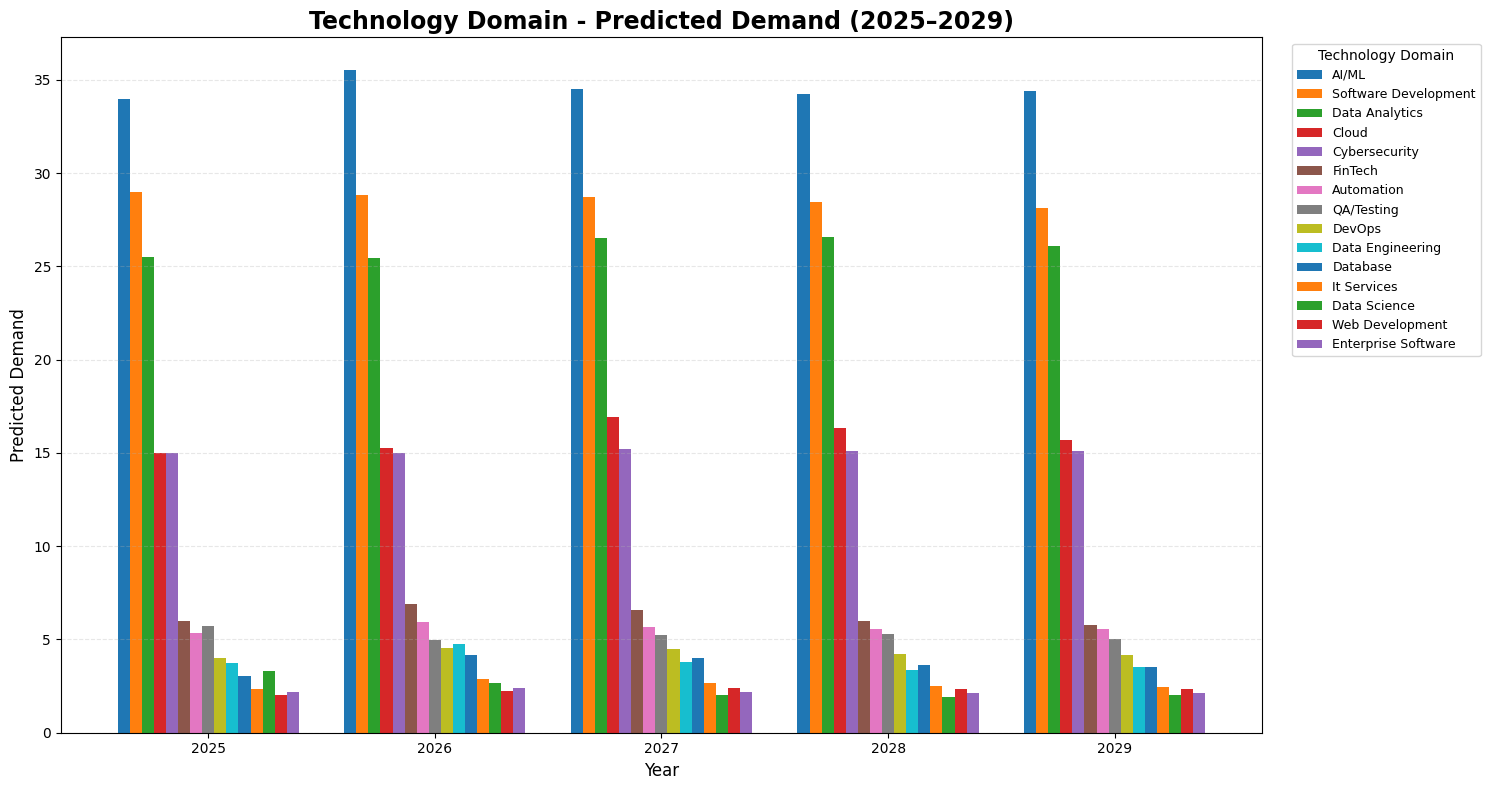

In [35]:
# ==========================================
# TOP PREDICTED TECHNOLOGIES
# ==========================================

# 2025-2029 ka average prediction
avg_prediction = prediction_df.mean(axis=0)

# Highest demand first
avg_prediction = avg_prediction.sort_values(
    ascending=False
)

# Top 15
top_15 = avg_prediction.head(15)


# ==========================================
# BAR GRAPH - YEAR ON X-AXIS
# ==========================================

# Selected top technologies
selected_technologies = top_15.index.tolist()

# 2025-2029 ka data
plot_data = prediction_df[
    selected_technologies
]


# ==========================================
# GRAPH
# ==========================================

ax = plot_data.plot(
    kind="bar",
    figsize=(15, 8),
    width=0.8
)

plt.xlabel(
    "Year",
    fontsize=12
)

plt.ylabel(
    "Predicted Demand",
    fontsize=12
)

plt.title(
    "Technology Domain - Predicted Demand (2025–2029)",
    fontsize=17,
    fontweight="bold"
)

# X-axis = years
plt.xticks(
    ticks=range(5),
    labels=["2025", "2026", "2027", "2028", "2029"],
    rotation=0
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

# Technology names in separate legend
plt.legend(
    title="Technology Domain",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9
)

plt.tight_layout()
plt.show()

Total technologies: 240


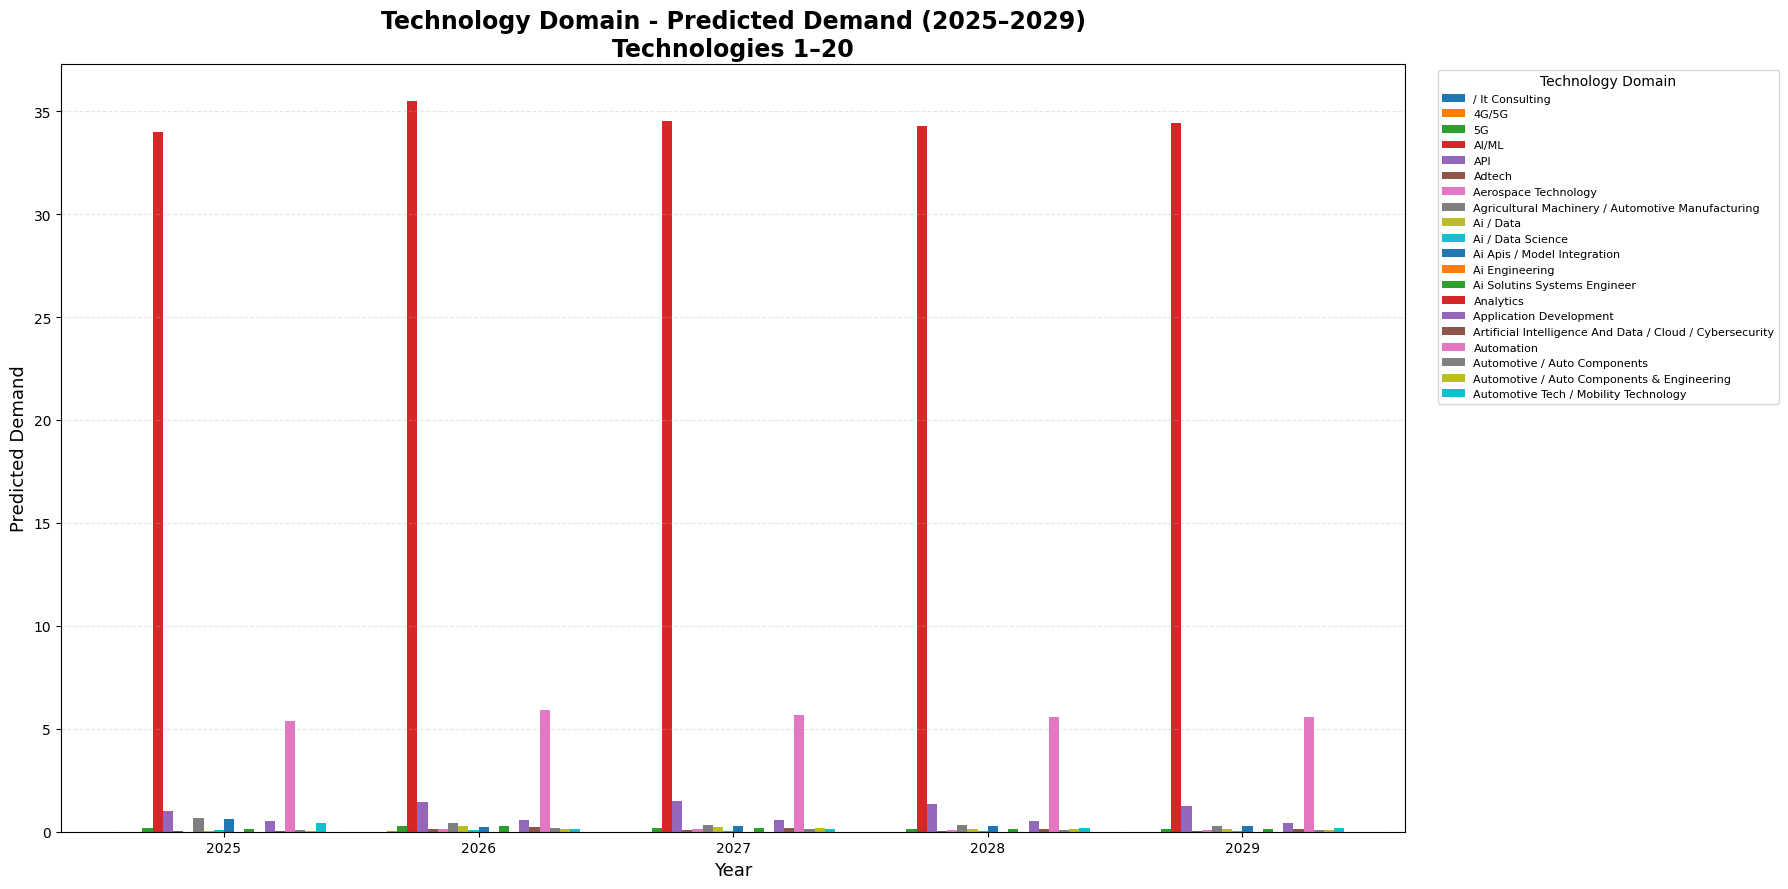

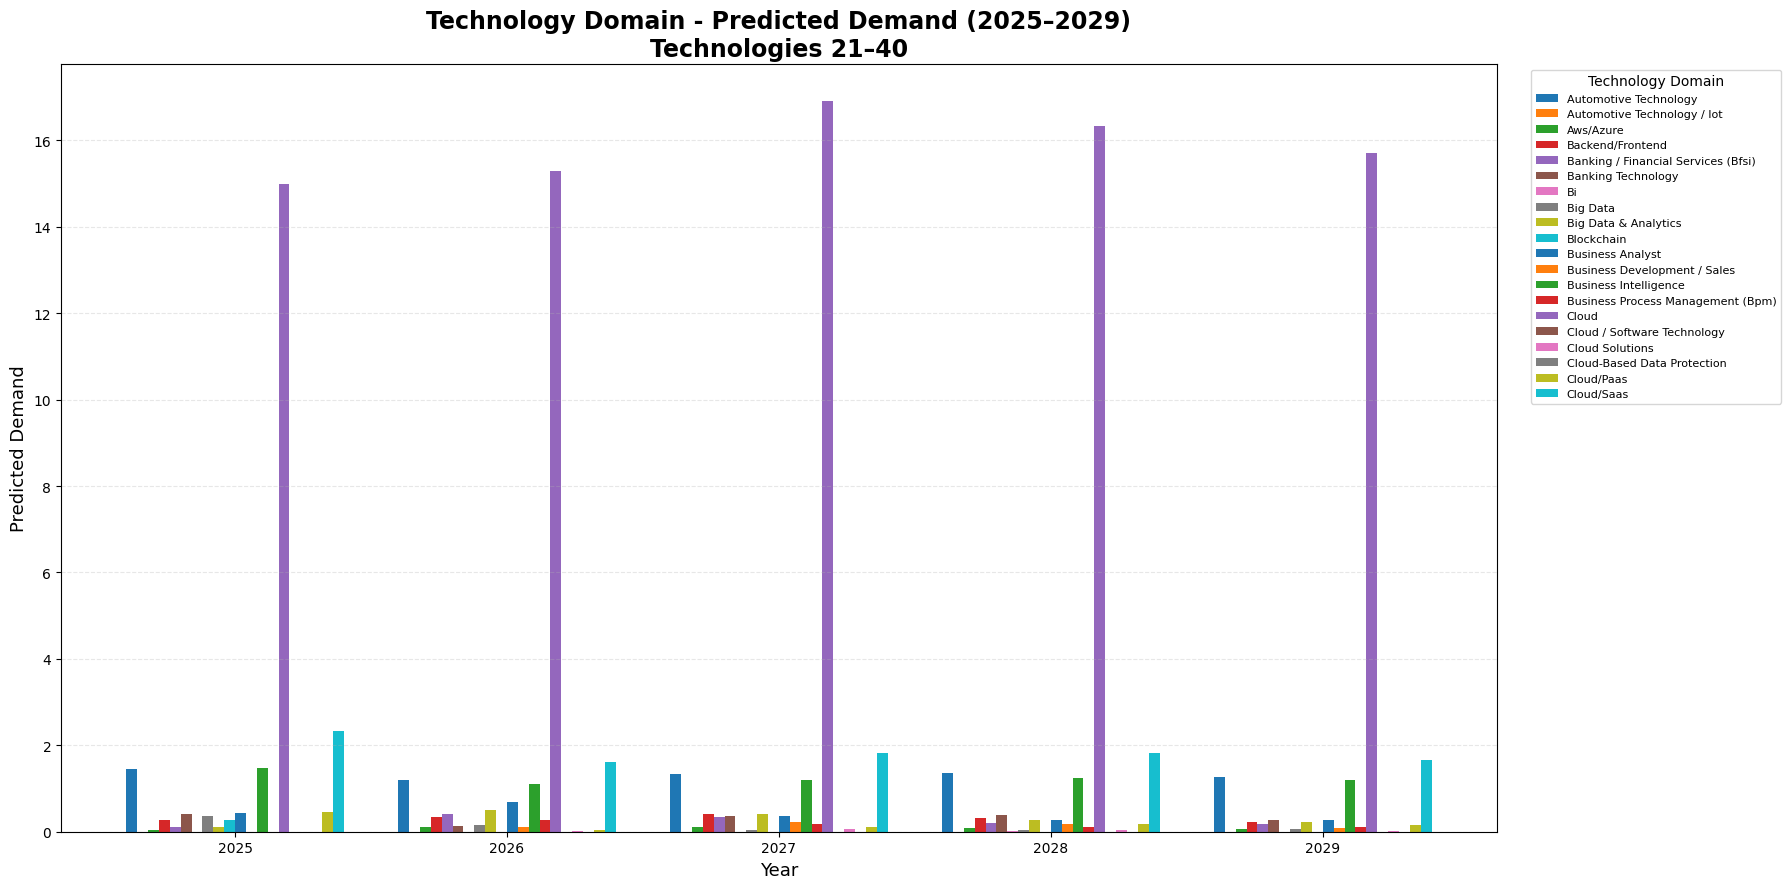

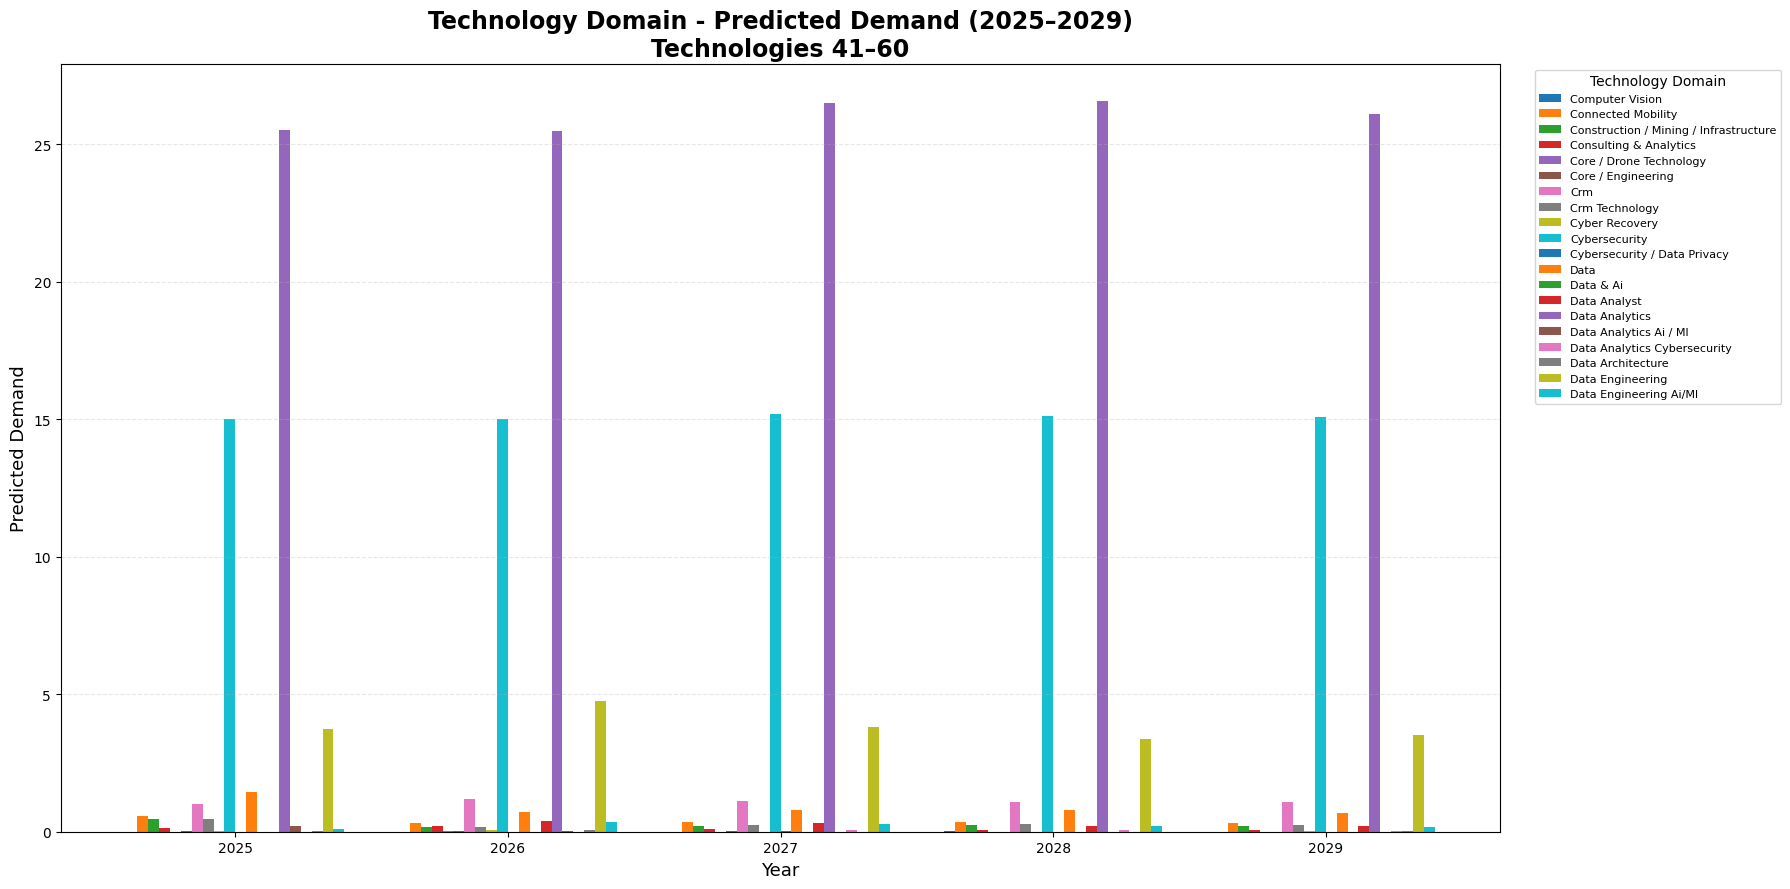

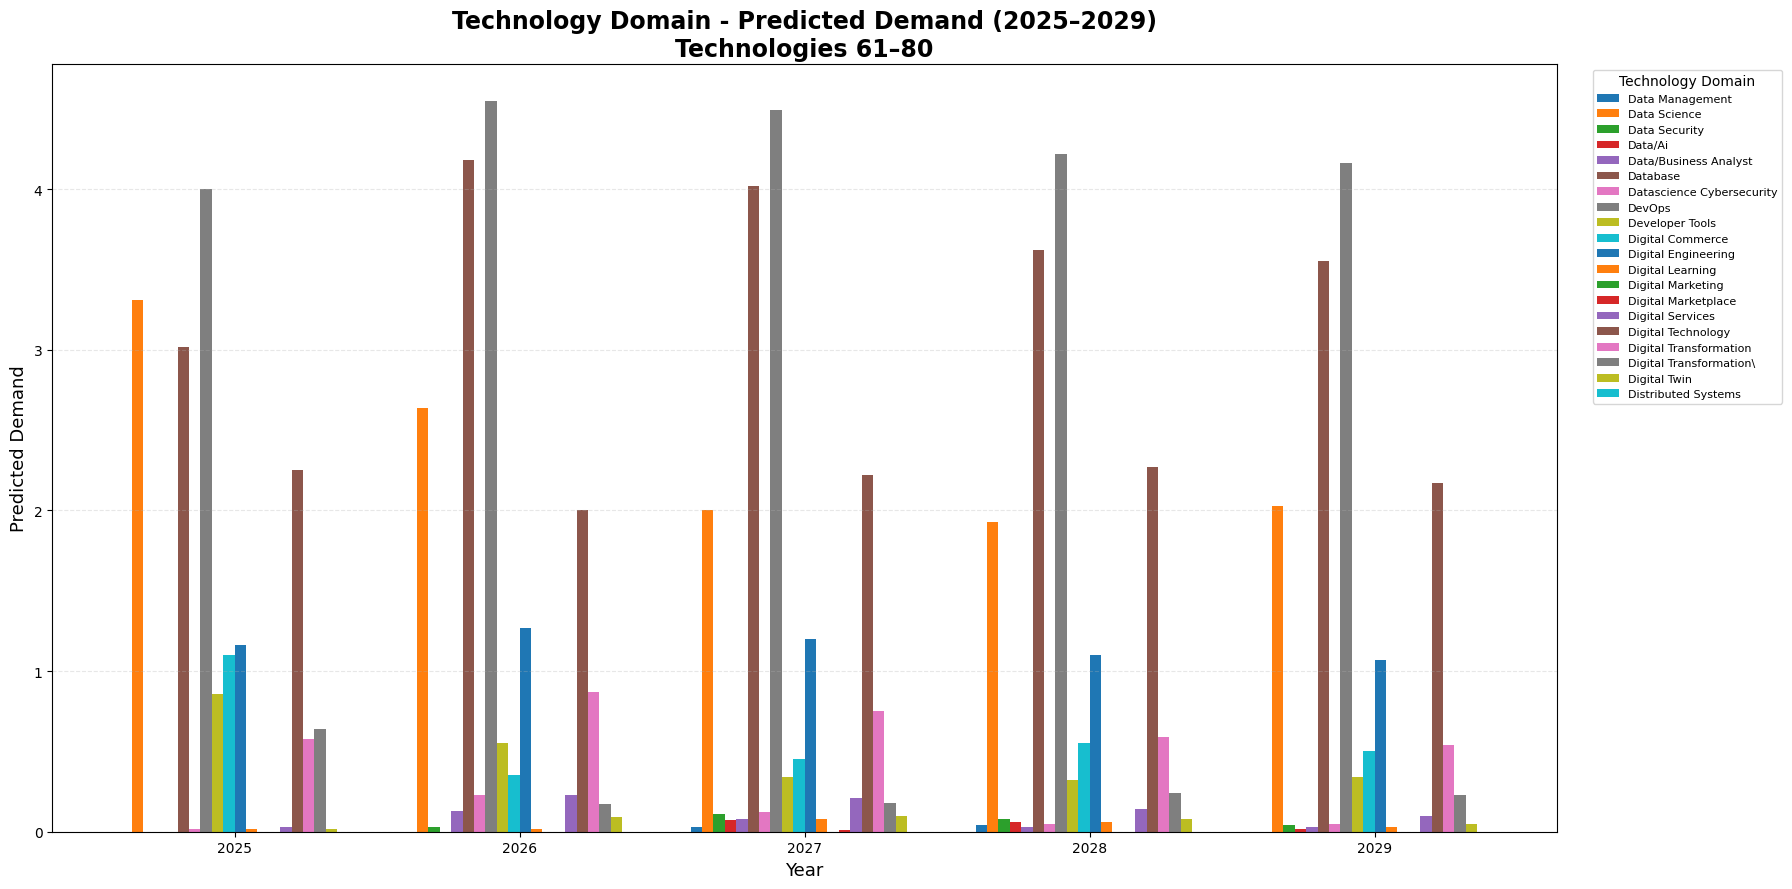

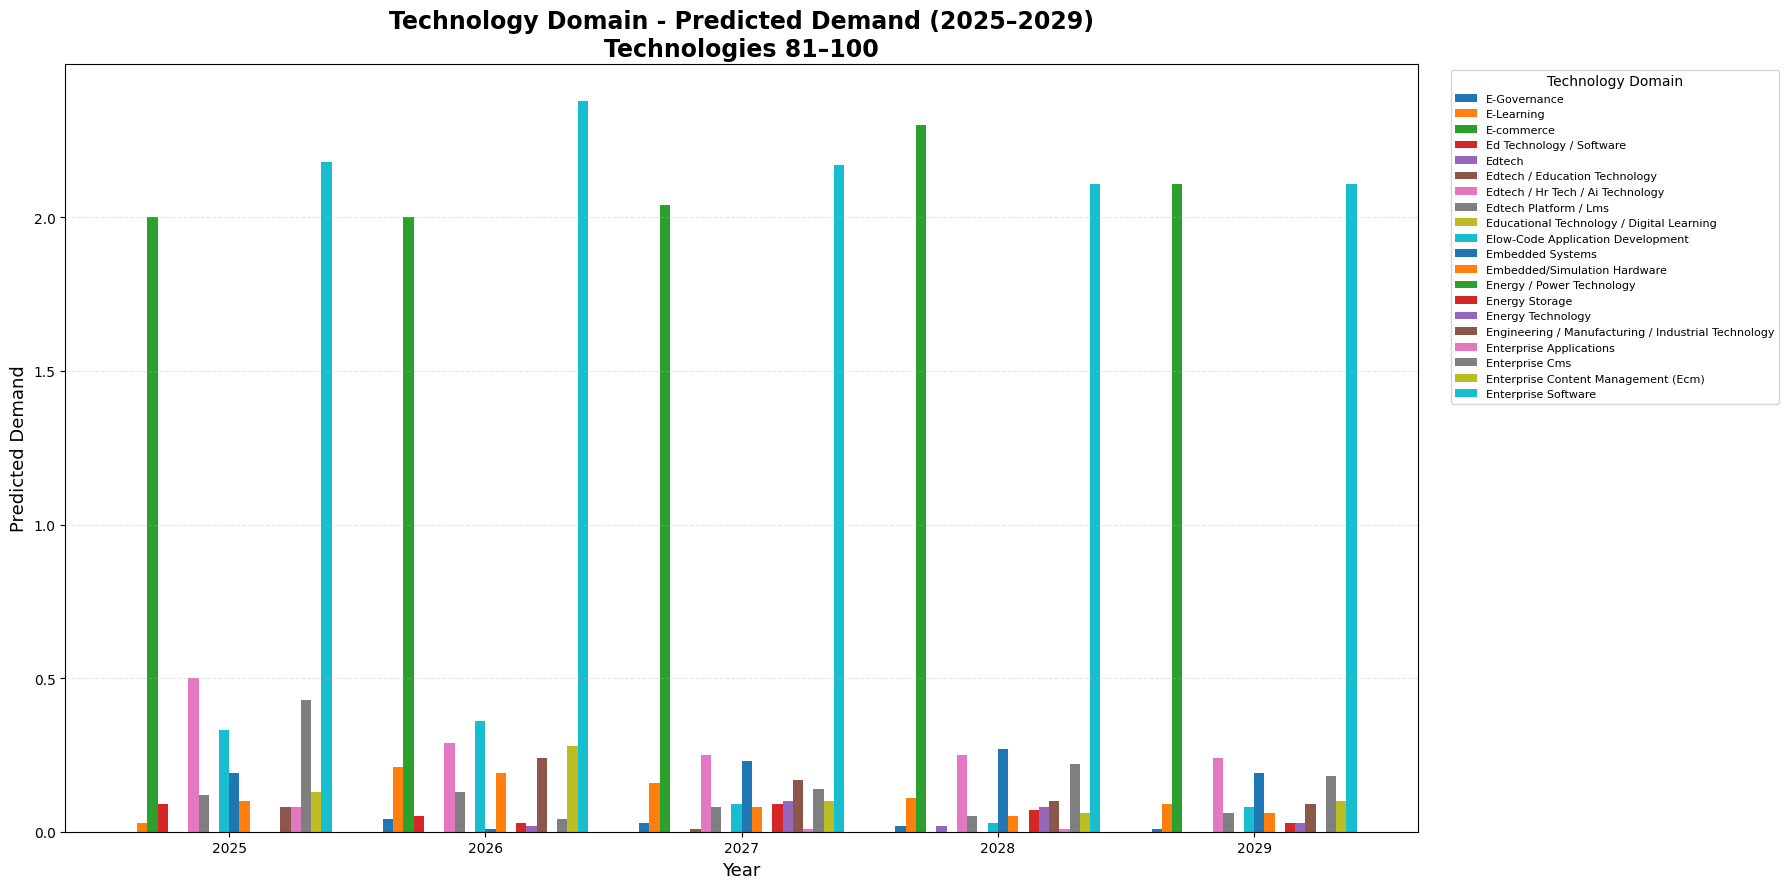

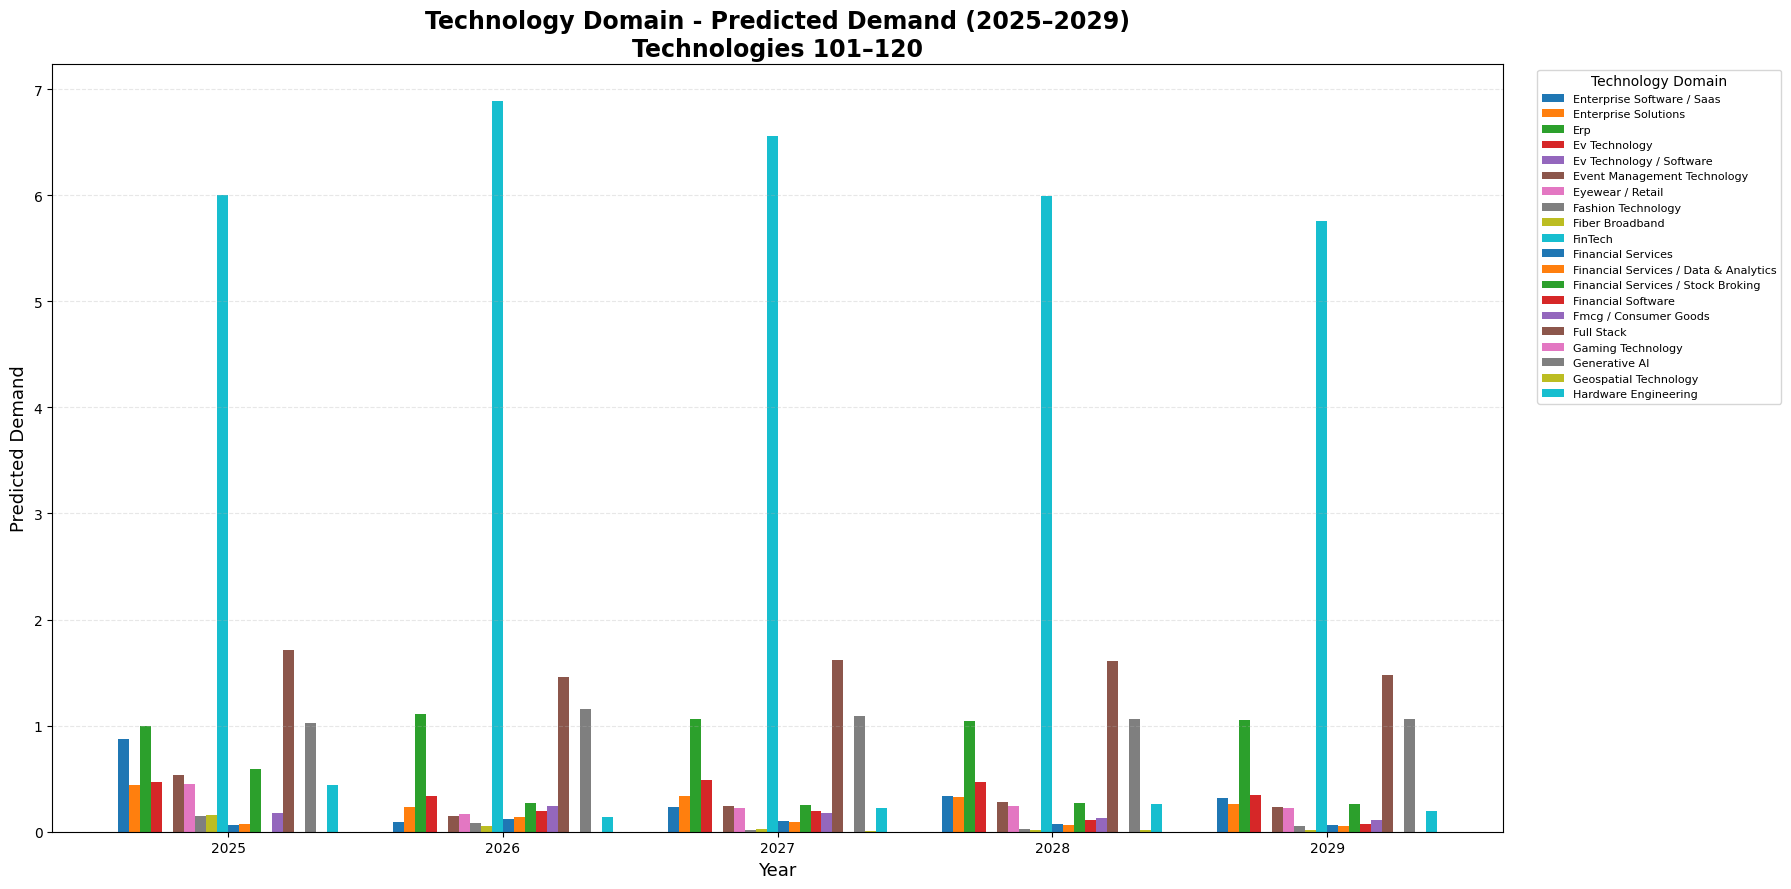

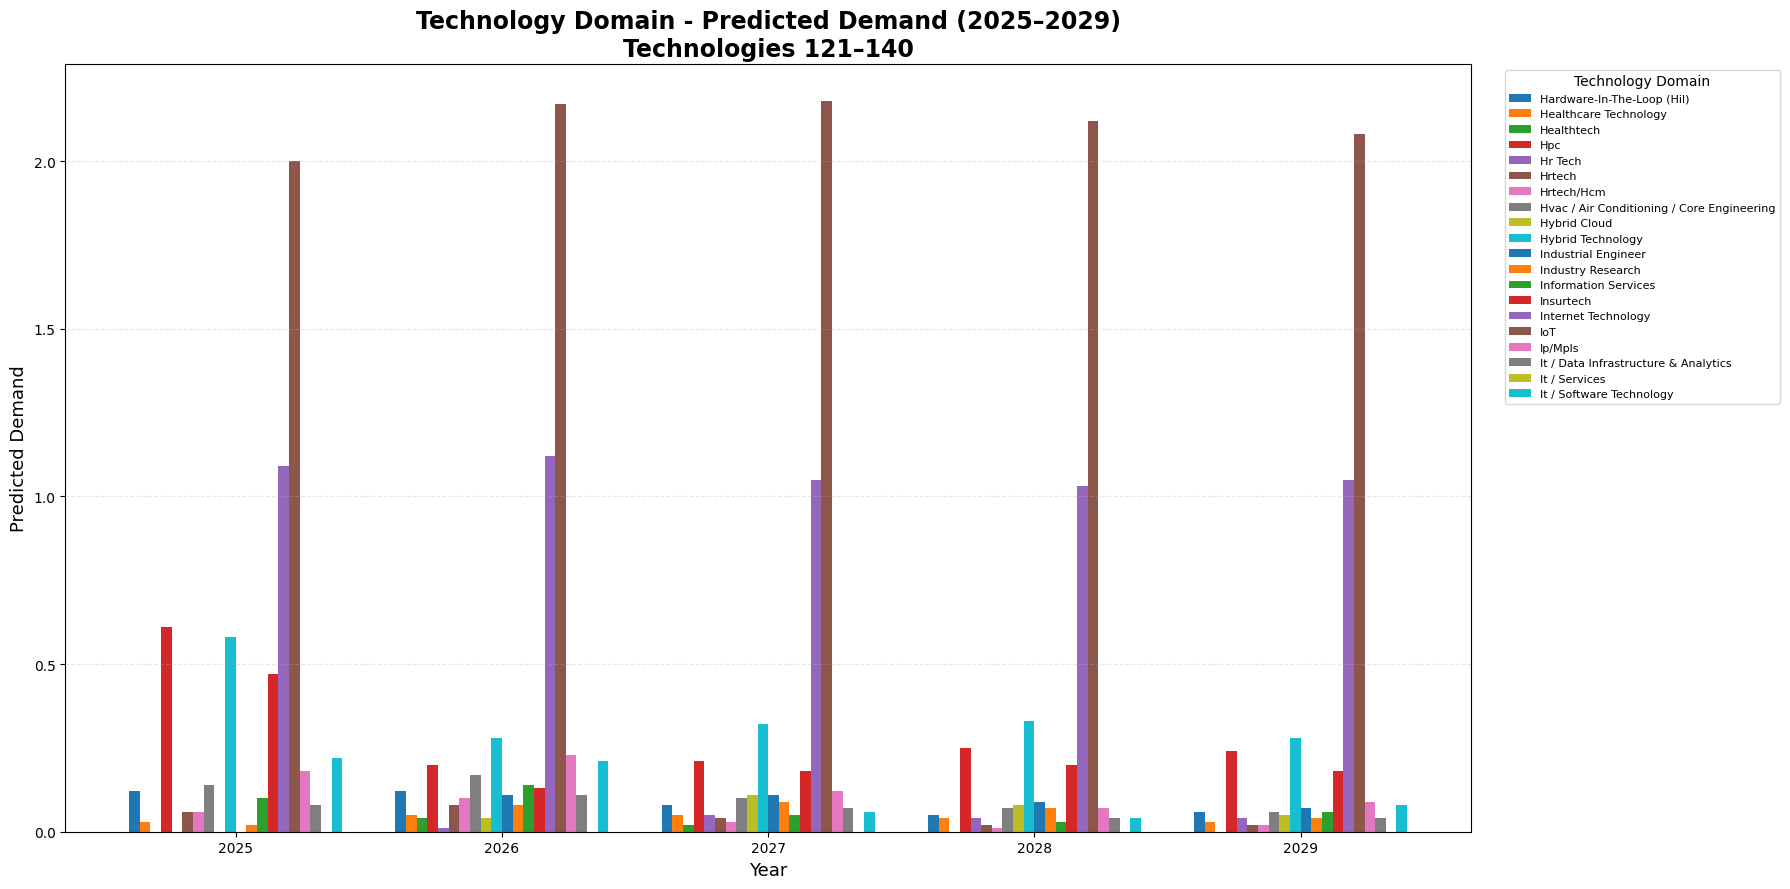

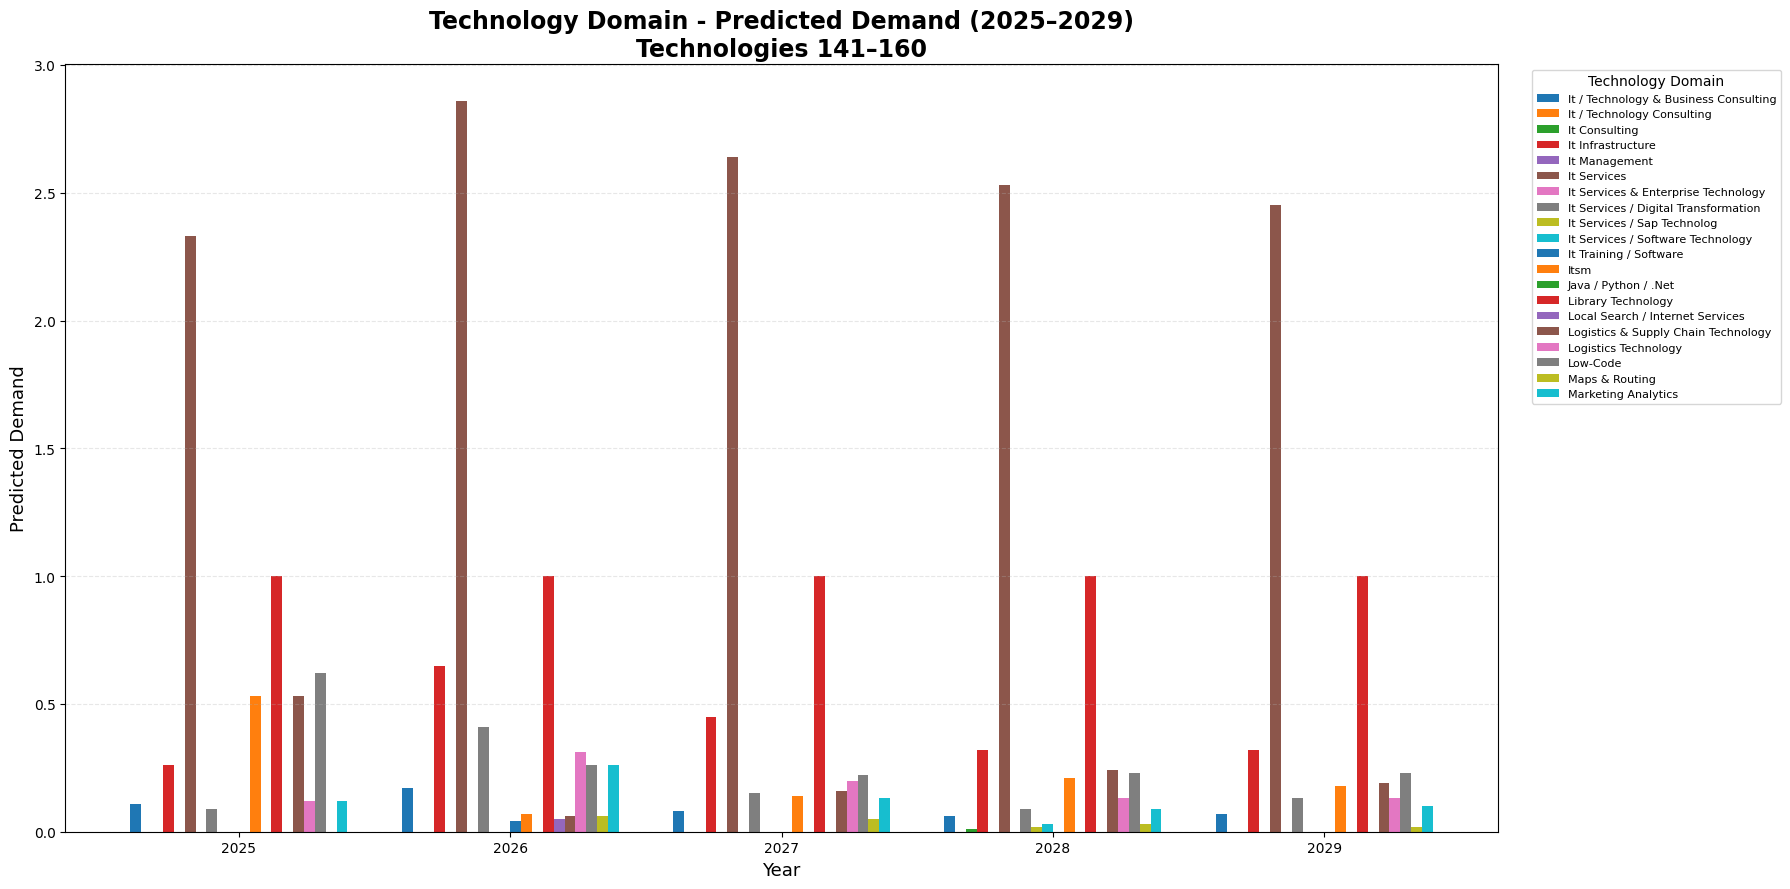

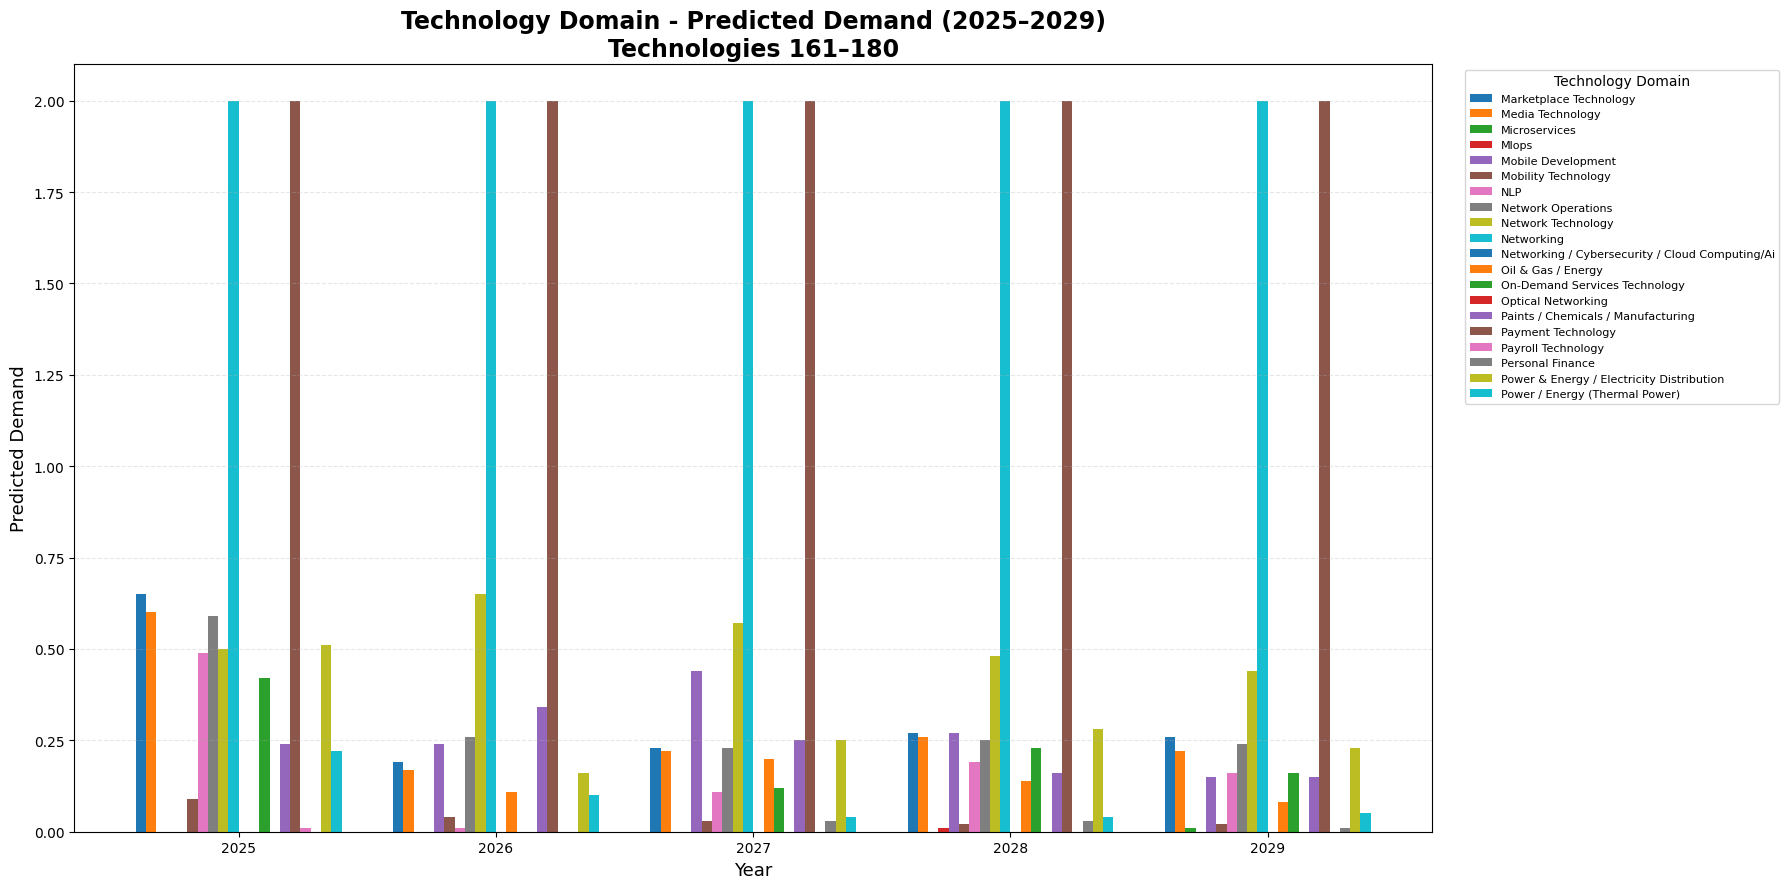

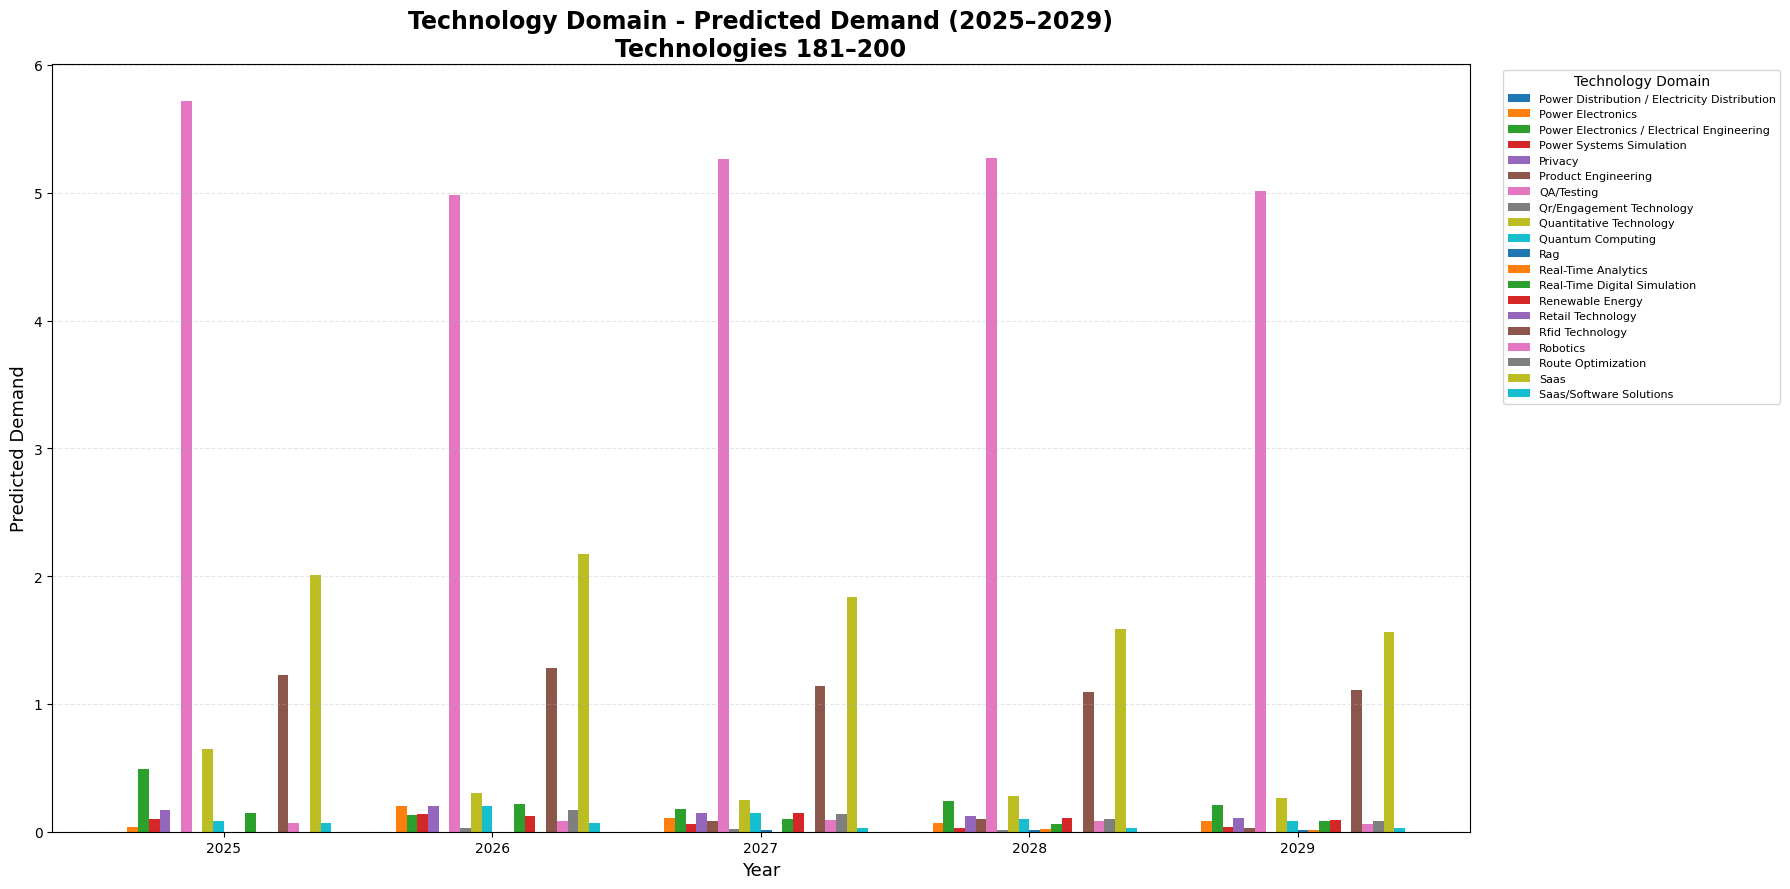

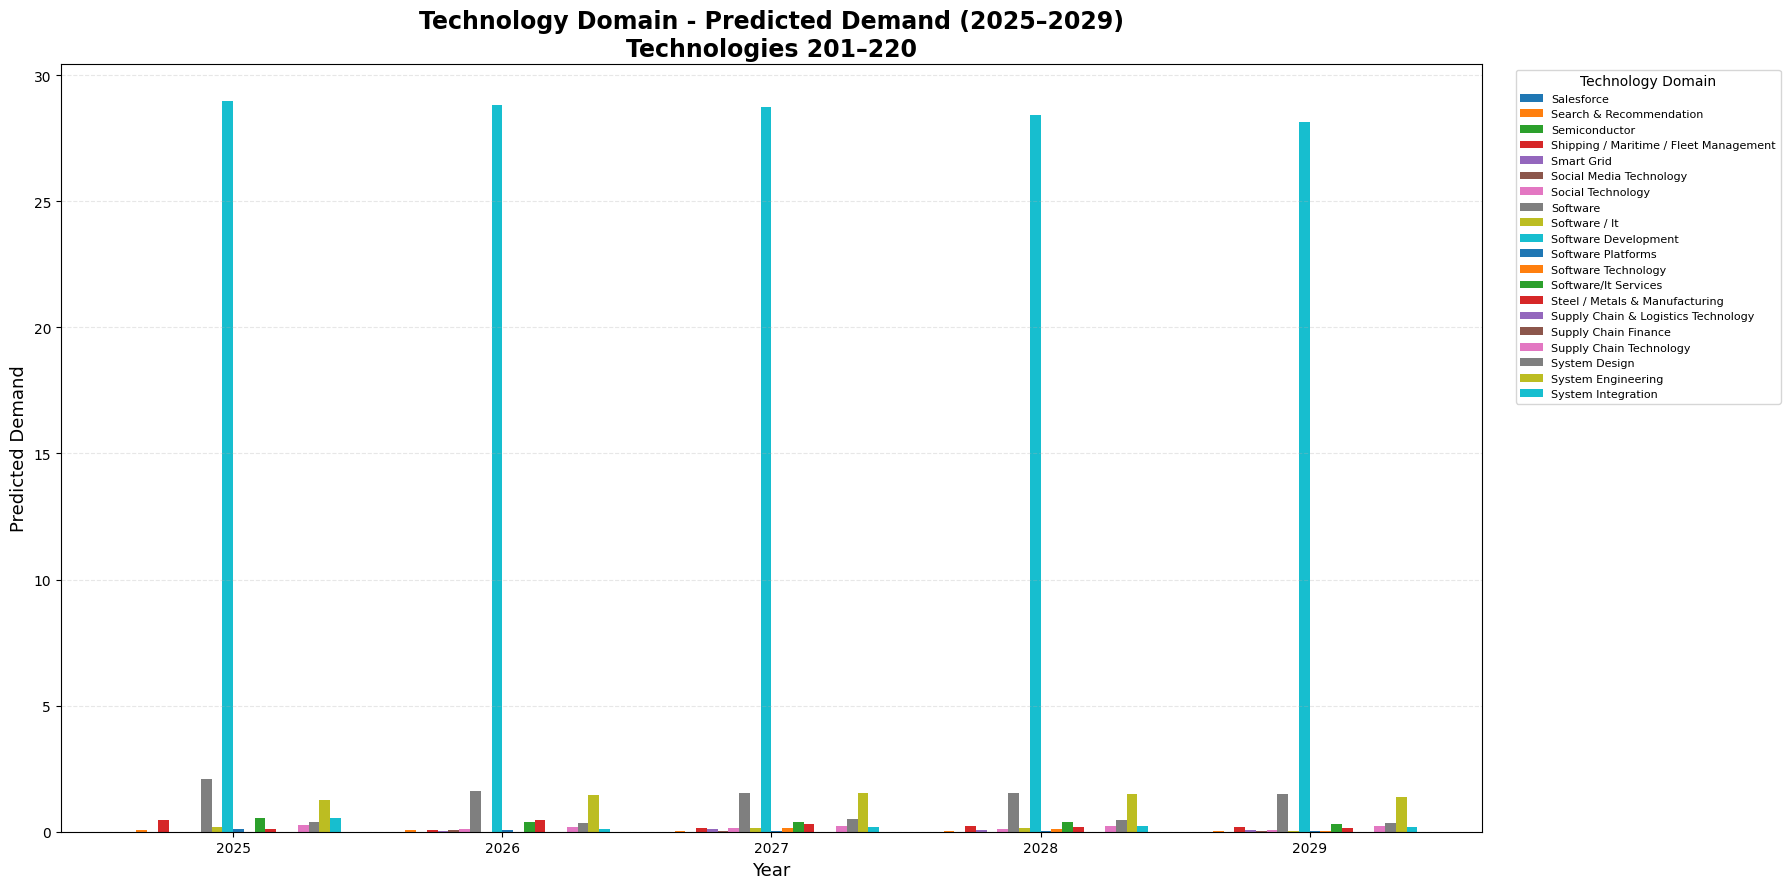

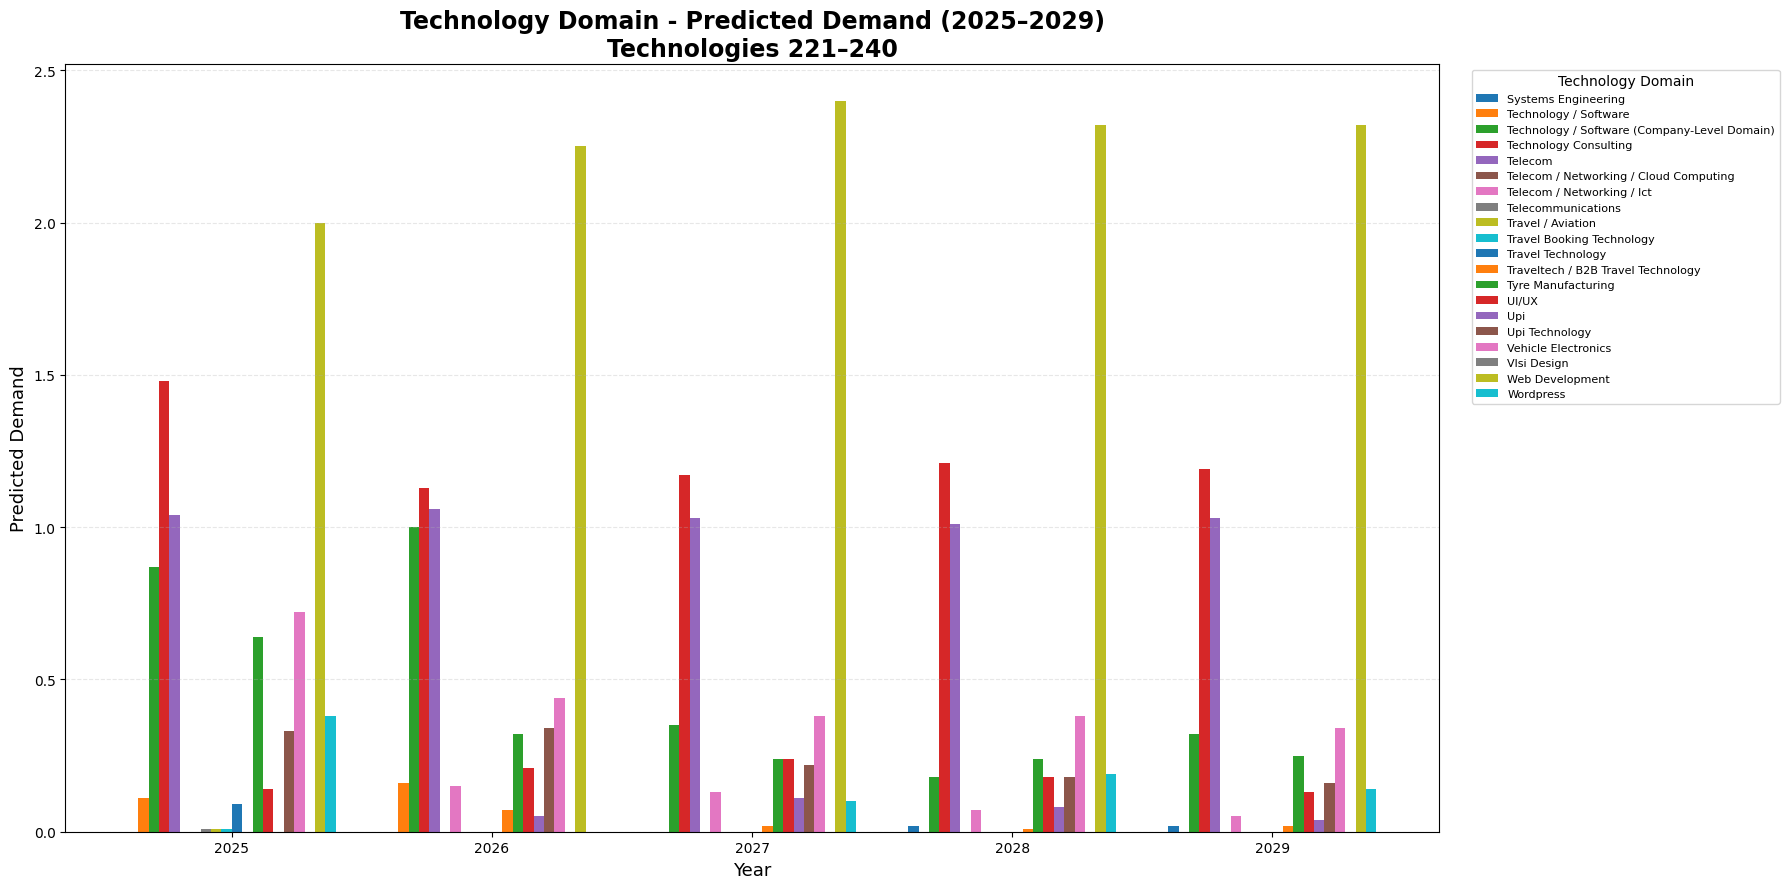

In [36]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# ALL TECHNOLOGIES - YEAR-WISE PREDICTION
# ==========================================

# Technology names
technologies = prediction_df.columns.tolist()

# Years
years = prediction_df.index.tolist()

# Number of technologies
n_tech = len(technologies)

print("Total technologies:", n_tech)


# ==========================================
# CREATE GRAPH IN BATCHES
# ==========================================

# 20 technologies per graph
batch_size = 20

for start in range(0, n_tech, batch_size):

    end = min(start + batch_size, n_tech)

    tech_batch = technologies[start:end]

    data = prediction_df[tech_batch]

    x = np.arange(len(years))

    # Width of each bar
    width = 0.8 / len(tech_batch)

    plt.figure(figsize=(18, 9))

    # --------------------------------------
    # Bars for every technology
    # --------------------------------------

    for i, tech in enumerate(tech_batch):

        values = data[tech].values

        offset = (
            i - (len(tech_batch) - 1) / 2
        ) * width

        plt.bar(
            x + offset,
            values,
            width=width,
            label=tech
        )


    # --------------------------------------
    # X-axis = Year
    # --------------------------------------

    plt.xlabel(
        "Year",
        fontsize=13
    )

    plt.ylabel(
        "Predicted Demand",
        fontsize=13
    )

    plt.xticks(
        x,
        years
    )


    # --------------------------------------
    # Title
    # --------------------------------------

    plt.title(
        f"Technology Domain - Predicted Demand "
        f"(2025–2029)\nTechnologies {start + 1}–{end}",
        fontsize=17,
        fontweight="bold"
    )


    # --------------------------------------
    # Grid
    # --------------------------------------

    plt.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )


    # --------------------------------------
    # Legend
    # --------------------------------------

    plt.legend(
        title="Technology Domain",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=8
    )


    plt.tight_layout()
    plt.show()

In [37]:
# Historical average demand (2020-2024)
historical_avg = technology_matrix.mean(axis=0)

# Predicted average demand (2025-2029)
predicted_avg = prediction_df.mean(axis=0)

# Create comparison dataframe
comparison_df = pd.DataFrame({
    "Historical Average Demand": historical_avg,
    "Predicted Average Demand": predicted_avg
})

# Calculate demand difference
comparison_df["Demand Change"] = (
    comparison_df["Predicted Average Demand"] -
    comparison_df["Historical Average Demand"]
)

# Calculate percentage change
comparison_df["Percentage Change"] = np.where(
    comparison_df["Historical Average Demand"] != 0,
    (
        comparison_df["Demand Change"] /
        comparison_df["Historical Average Demand"]
    ) * 100,
    np.nan
)

comparison_df = comparison_df.sort_values(
    "Predicted Average Demand",
    ascending=False
)

display(comparison_df.round(2))

,Historical Average Demand,Predicted Average Demand,Demand Change,Percentage Change
Technology,,,,
AI/ML,41.4,34.549999,-6.85,-16.55
Software Development,38.6,28.620001,-9.98,-25.84
Data Analytics,33.4,26.040001,-7.36,-22.02
Cloud,25.4,15.850000,-9.55,-37.61
Cybersecurity,19.8,15.090000,-4.71,-23.81
...,...,...,...,...
Power Distribution / Electricity Distribution,0.2,0.000000,-0.20,-100.00
Supply Chain & Logistics Technology,0.2,0.000000,-0.20,-100.00
Supply Chain Finance,0.2,0.000000,-0.20,-100.00


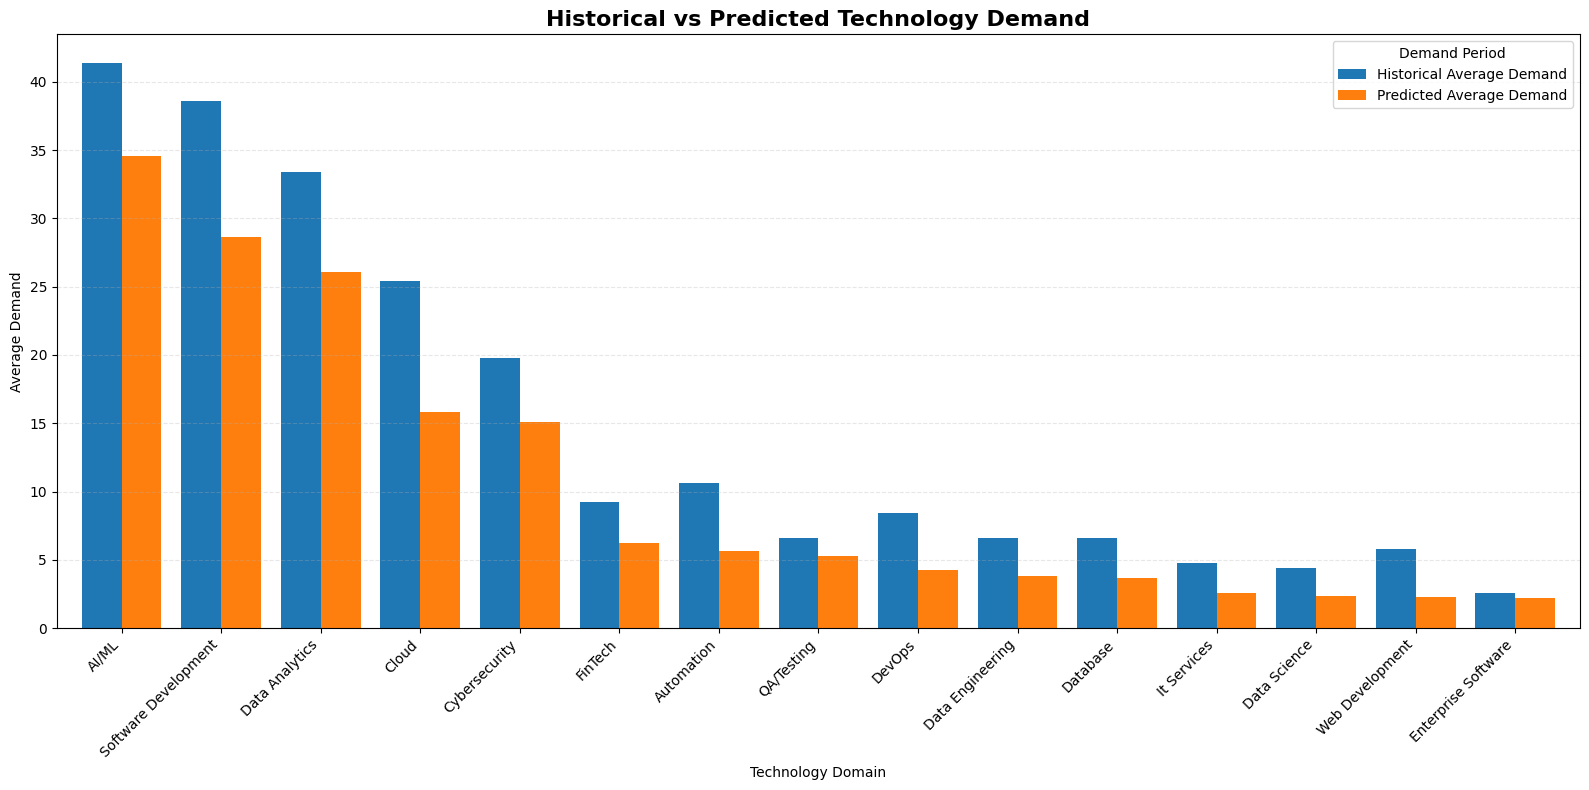

In [38]:
top_15 = comparison_df.head(15)

top_15[
    ["Historical Average Demand", "Predicted Average Demand"]
].plot(
    kind="bar",
    figsize=(16, 8),
    width=0.8
)

plt.title(
    "Historical vs Predicted Technology Demand",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Technology Domain")
plt.ylabel("Average Demand")

plt.xticks(rotation=45, ha="right")
plt.legend(title="Demand Period")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [39]:
# Top 10 increasing technologies
increasing = comparison_df.sort_values(
    "Demand Change",
    ascending=False
).head(10)

print("Top 10 Technologies with Increasing Predicted Demand")
display(increasing.round(2))

# Top 10 decreasing technologies
decreasing = comparison_df.sort_values(
    "Demand Change",
    ascending=True
).head(10)

print("Top 10 Technologies with Decreasing Predicted Demand")
display(decreasing.round(2))

Top 10 Technologies with Increasing Predicted Demand


,Historical Average Demand,Predicted Average Demand,Demand Change,Percentage Change
Technology,,,,
Agricultural Machinery / Automotive Manufacturing,0.2,0.40,0.20,100.0
Digital Commerce,0.4,0.59,0.19,47.5
Tyre Manufacturing,0.2,0.34,0.14,69.0
Ai Apis / Model Integration,0.2,0.34,0.14,69.0
Financial Services / Stock Broking,0.2,0.33,0.13,64.0
Network Operations,0.2,0.31,0.11,57.0
Edtech / Hr Tech / Ai Technology,0.2,0.31,0.11,53.0
Hpc,0.2,0.30,0.10,51.0
Media Technology,0.2,0.29,0.09,47.0


Top 10 Technologies with Decreasing Predicted Demand


,Historical Average Demand,Predicted Average Demand,Demand Change,Percentage Change
Technology,,,,
Software Development,38.6,28.620001,-9.98,-25.84
Cloud,25.4,15.850000,-9.55,-37.61
Data Analytics,33.4,26.040001,-7.36,-22.02
AI/ML,41.4,34.549999,-6.85,-16.55
Automation,10.6,5.610000,-4.99,-47.08
Cybersecurity,19.8,15.090000,-4.71,-23.81
API,5.6,1.300000,-4.30,-76.82
DevOps,8.4,4.280000,-4.12,-49.00
Web Development,5.8,2.260000,-3.54,-61.07


In [40]:
# Five colleges
college_order = [
    "DTU", "IGDTUW", "MAIT", "BPIT", "IIIT_Delhi"
]

# Create technology sets for each college
college_technologies = {}

for college in college_order:

    technologies = set(
        domain_df[
            domain_df["College"] == college
        ]["Technology Domain"].dropna()
    )

    college_technologies[college] = technologies

# Find common technologies
common_technologies = set.intersection(
    *college_technologies.values()
)

print("Technologies Common Across All Five Colleges:")
print("Total Common Technologies:", len(common_technologies))

for tech in sorted(common_technologies):
    print(tech)

Technologies Common Across All Five Colleges:
Total Common Technologies: 12
AI/ML
Cloud
Cybersecurity
Data & Analytics
Data Analytics
DevOps
FinTech
IoT
Networking
SaaS
Software Development
Software Engineering


In [41]:
unique_technologies = {}

for college in college_order:

    other_colleges = set.union(
        *[
            college_technologies[c]
            for c in college_order
            if c != college
        ]
    )

    unique = (
        college_technologies[college] - other_colleges
    )

    unique_technologies[college] = unique

    print(f"\n{'='*45}")
    print(f"UNIQUE TECHNOLOGIES - {college}")
    print(f"{'='*45}")

    print("Total Unique:", len(unique))

    for tech in sorted(unique):
        print(tech)


UNIQUE TECHNOLOGIES - DTU
Total Unique: 3
Connected Car/Telematics
Hybrid & EV Technology
Vehicle Safety

UNIQUE TECHNOLOGIES - IGDTUW
Total Unique: 28
ADI Technology
AIOps
Adaptive Learning
Advanced Optics
Agentic AI
Application Performance Monitoring
CX Technology
Conversational AI
Data Streaming
Digital Health
Digital Retail
Fashion Technology
FinTech / Quantitative Technology
Gaming Technology
HRTech/HCM
Healthcare IT
IT Management
Maps & Routing
Materials Science
Mobility Technology
Online Assessment
Optical Communications
Payroll Technology
Search Technology
Speech Analytics
Stream Processing
Supply Chain & Logistics Technology
Supply Chain Finance

UNIQUE TECHNOLOGIES - MAIT
Total Unique: 217
5G
AI / Data
AI / Data Science
AI / Machine Learning
AI APIs / Model Integration
AI Engineering
AI Solutins Systems Engineer
AI/GenAI
API
API / Software Technology
API / System Integration
Technology Consulting
API Development
API Development / Integration
API/Integration
APIs
APIs / Backe

In [42]:
# Create technology presence matrix
presence_matrix = pd.DataFrame(index=sorted(
    set.union(*college_technologies.values())
))

for college in college_order:

    presence_matrix[college] = (
        presence_matrix.index.isin(
            college_technologies[college]
        ).astype(int)
    )

# Count colleges containing each technology
presence_matrix["College Count"] = (
    presence_matrix[college_order].sum(axis=1)
)

# Sort by number of colleges
presence_matrix = presence_matrix.sort_values(
    "College Count",
    ascending=False
)

display(presence_matrix)

,DTU,IGDTUW,MAIT,BPIT,IIIT_Delhi,College Count
Networking,1,1,1,1,1,5
Cloud,1,1,1,1,1,5
SaaS,1,1,1,1,1,5
Software Engineering,1,1,1,1,1,5
Software Development,1,1,1,1,1,5
...,...,...,...,...,...,...
analytics,0,0,1,0,0,1
TravelTech / B2B Travel Technology,0,0,1,0,0,1
Tyre Manufacturing,0,0,1,0,0,1
UI/UX,0,0,1,0,0,1


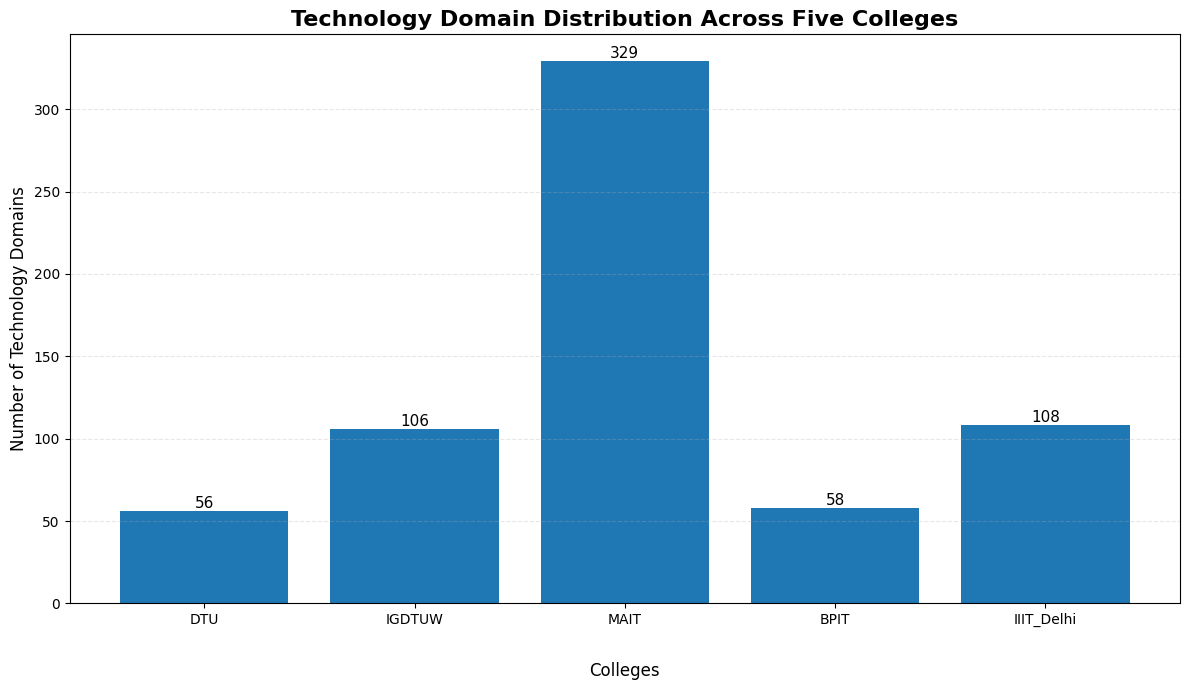

In [43]:
# Count technologies for each college
college_tech_counts = (
    presence_matrix[college_order].sum(axis=0)
)

plt.figure(figsize=(12, 7))

bars = plt.bar(
    college_tech_counts.index,
    college_tech_counts.values
)

# Show count above each bar
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        int(height),
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.title(
    "Technology Domain Distribution Across Five Colleges",
    fontsize=16,
    fontweight="bold"
)

# Increased distance between college names and X-axis label
plt.xlabel("Colleges", fontsize=12, labelpad=25)

plt.ylabel("Number of Technology Domains", fontsize=12)

plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [44]:
# College-wise technology sets
college_order = [
    "DTU",
    "IGDTUW",
    "MAIT",
    "BPIT",
    "IIIT_Delhi"
]

# Create similarity matrix
similarity_matrix = pd.DataFrame(
    index=college_order,
    columns=college_order,
    dtype=float
)

for college1 in college_order:

    for college2 in college_order:

        set1 = college_technologies[college1]
        set2 = college_technologies[college2]

        intersection = len(set1.intersection(set2))
        union = len(set1.union(set2))

        similarity = (
            intersection / union * 100
            if union != 0 else 0
        )

        similarity_matrix.loc[
            college1, college2
        ] = similarity

print("College Similarity Percentage:")
display(similarity_matrix.round(2))

College Similarity Percentage:


,DTU,IGDTUW,MAIT,BPIT,IIIT_Delhi
DTU,100.00,24.62,10.00,12.87,37.82
IGDTUW,24.62,100.00,18.53,17.99,22.29
MAIT,10.00,18.53,100.00,14.16,14.40
BPIT,12.87,17.99,14.16,100.00,13.70
IIIT_Delhi,37.82,22.29,14.40,13.70,100.00


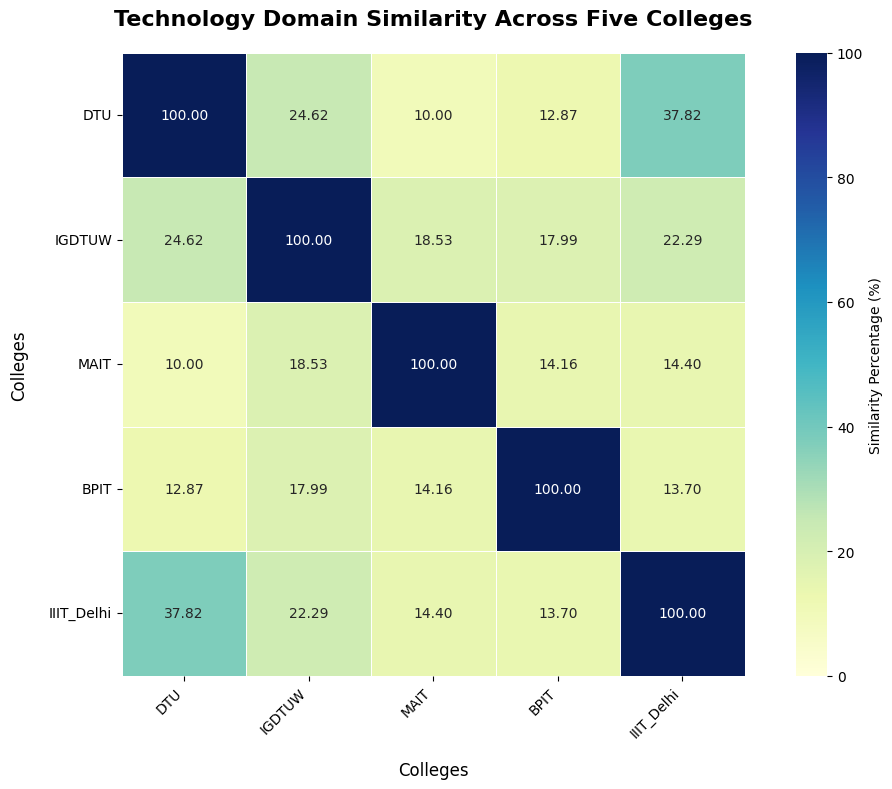

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Convert similarity values into percentage
if similarity_matrix.max().max() <= 1:
    similarity_percentage = similarity_matrix * 100
else:
    similarity_percentage = similarity_matrix.copy()

# Create figure
plt.figure(figsize=(11, 8))

# Generate heatmap
sns.heatmap(
    similarity_percentage.astype(float),
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    square=True,
    vmin=0,
    vmax=100,
    cbar_kws={
        "label": "Similarity Percentage (%)"
    }
)

# Add title
plt.title(
    "Technology Domain Similarity Across Five Colleges",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Colleges", fontsize=12, labelpad=15)
plt.ylabel("Colleges", fontsize=12, labelpad=15)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [48]:
# Remove diagonal and duplicate pairs
similarity_pairs = similarity_matrix.copy()

np.fill_diagonal(similarity_pairs.values, np.nan)

pairs = similarity_pairs.stack().reset_index()

pairs.columns = [
    "College 1",
    "College 2",
    "Similarity (%)"
]

pairs = pairs[
    pairs["College 1"] < pairs["College 2"]
].sort_values(
    "Similarity (%)",
    ascending=False
)

print("Most Similar College Pairs:")
display(pairs)

Most Similar College Pairs:


,College 1,College 2,Similarity (%)
3,DTU,IIIT_Delhi,37.815126
0,DTU,IGDTUW,24.615385
7,IGDTUW,IIIT_Delhi,22.285714
5,IGDTUW,MAIT,18.528610
13,BPIT,IGDTUW,17.985612
18,IIIT_Delhi,MAIT,14.397906
14,BPIT,MAIT,14.159292
15,BPIT,IIIT_Delhi,13.698630
12,BPIT,DTU,12.871287
1,DTU,MAIT,10.000000


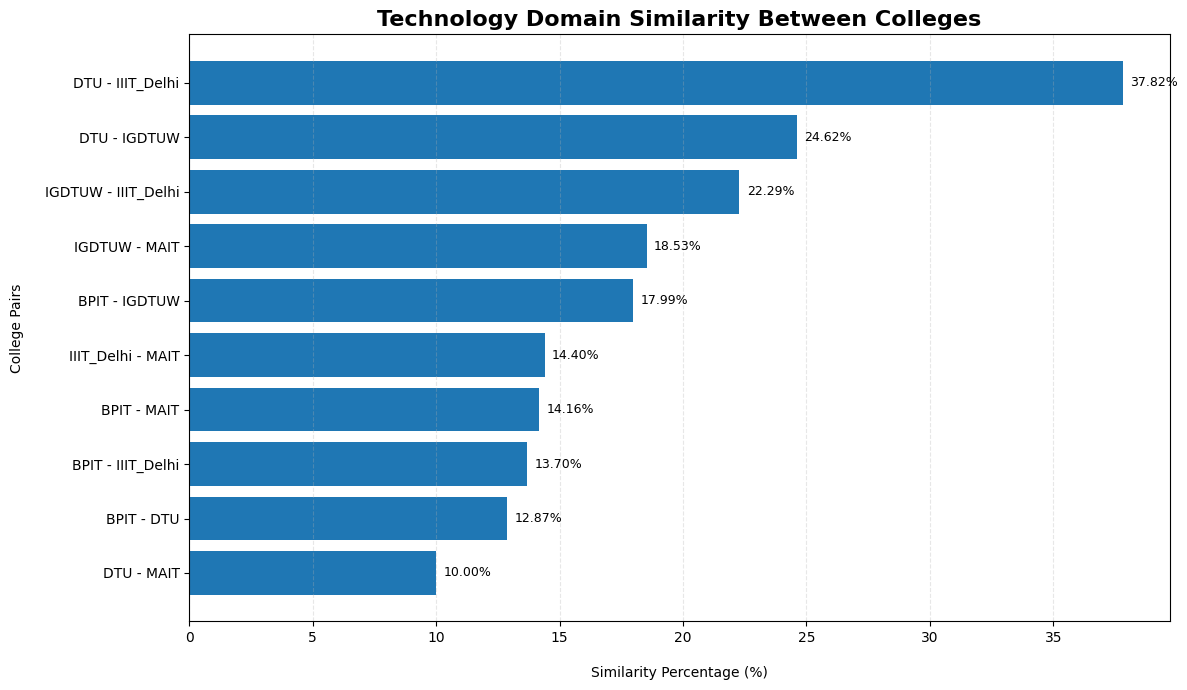

In [49]:
# College similarity comparison graph

plt.figure(figsize=(12, 7))

pairs["College Pair"] = (
    pairs["College 1"] + " - " + pairs["College 2"]
)

sorted_pairs = pairs.sort_values(
    "Similarity (%)",
    ascending=True
)

bars = plt.barh(
    sorted_pairs["College Pair"],
    sorted_pairs["Similarity (%)"]
)

for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 0.3,
        bar.get_y() + bar.get_height()/2,
        f"{width:.2f}%",
        va="center",
        fontsize=9
    )

plt.title(
    "Technology Domain Similarity Between Colleges",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Similarity Percentage (%)", labelpad=15)
plt.ylabel("College Pairs", labelpad=15)

plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [50]:
import pandas as pd
from IPython.display import display

college_order = ["DTU", "IGDTUW", "MAIT", "BPIT", "IIIT_Delhi"]

for college in college_order:

    print("\n" + "=" * 65)
    print(f"COLLEGE: {college}")
    print("=" * 65)

    # Historical technology demand for this college
    college_historical = (
        domain_df[domain_df["College"] == college]
        ["Technology Domain"]
        .value_counts()
    )

    # Match technologies with combined model predictions
    college_comparison = pd.DataFrame({
        "Historical Demand": college_historical
    })

    college_comparison["Predicted Average Demand"] = (
        comparison_df["Predicted Average Demand"]
    )

    college_comparison = college_comparison.dropna(
        subset=["Predicted Average Demand"]
    )

    college_comparison["Demand Change"] = (
        college_comparison["Predicted Average Demand"]
        - college_comparison["Historical Demand"]
    )

    # Top 10 technologies by predicted demand
    print("\nTOP 10 TECHNOLOGIES BY PREDICTED DEMAND")

    display(
        college_comparison.sort_values(
            "Predicted Average Demand",
            ascending=False
        ).head(10).round(2)
    )

    # Top 10 increasing technologies
    print("\nTOP 10 INCREASING TECHNOLOGIES")

    display(
        college_comparison.sort_values(
            "Demand Change",
            ascending=False
        ).head(10).round(2)
    )

    # Top 10 decreasing technologies
    print("\nTOP 10 DECREASING TECHNOLOGIES")

    display(
        college_comparison.sort_values(
            "Demand Change",
            ascending=True
        ).head(10).round(2)
    )


COLLEGE: DTU

TOP 10 TECHNOLOGIES BY PREDICTED DEMAND


,Historical Demand,Predicted Average Demand,Demand Change
Technology Domain,,,
AI/ML,9,34.549999,25.55
Software Development,1,28.620001,27.62
Data Analytics,1,26.040001,25.04
Cloud,3,15.850000,12.85
Cybersecurity,6,15.090000,9.09
FinTech,1,6.240000,5.24
DevOps,1,4.280000,3.28
Enterprise Software,1,2.190000,1.19
IoT,3,2.110000,-0.89



TOP 10 INCREASING TECHNOLOGIES


,Historical Demand,Predicted Average Demand,Demand Change
Technology Domain,,,
Software Development,1,28.620001,27.62
AI/ML,9,34.549999,25.55
Data Analytics,1,26.040001,25.04
Cloud,3,15.850000,12.85
Cybersecurity,6,15.090000,9.09
FinTech,1,6.240000,5.24
DevOps,1,4.280000,3.28
Enterprise Software,1,2.190000,1.19
System Engineering,1,1.430000,0.43



TOP 10 DECREASING TECHNOLOGIES


,Historical Demand,Predicted Average Demand,Demand Change
Technology Domain,,,
Semiconductor,4,0.00,-4.00
Application Development,2,0.52,-1.48
Networking,3,2.00,-1.00
Telecom / Networking / Cloud Computing,1,0.00,-1.00
Systems Engineering,1,0.01,-0.99
IoT,3,2.11,-0.89
Big Data,1,0.13,-0.87
Embedded Systems,1,0.18,-0.82
Automotive Technology,2,1.32,-0.68


... (20 outputs left out)


TOP 10 INCREASING TECHNOLOGIES


,Historical Demand,Predicted Average Demand,Demand Change
Technology Domain,,,
Software Development,1,28.620001,27.62
Data Analytics,4,26.040001,22.04
AI/ML,18,34.549999,16.55
Cloud,9,15.850000,6.85
Automation,2,5.610000,3.61
DevOps,1,4.280000,3.28
Cybersecurity,12,15.090000,3.09
Data Engineering,2,3.840000,1.84
FinTech,5,6.240000,1.24



TOP 10 DECREASING TECHNOLOGIES


,Historical Demand,Predicted Average Demand,Demand Change
Technology Domain,,,
Semiconductor,6,0.00,-6.00
Networking,7,2.00,-5.00
IoT,5,2.11,-2.89
Robotics,2,0.08,-1.92
Embedded Systems,2,0.18,-1.82
Application Development,2,0.52,-1.48
Software,3,1.66,-1.34
Optical Networking,1,0.00,-1.00
Systems Engineering,1,0.01,-0.99


In [51]:
print("COLLEGE-WISE TECHNOLOGY DIVERSITY")

display(
    college_tech_counts.sort_values(
        ascending=False
    ).to_frame(name="Technology Domains")
)

print("\nCOMMON TECHNOLOGIES ACROSS ALL COLLEGES:")
print("Total:", len(common_technologies))

print("\nUNIQUE TECHNOLOGIES BY COLLEGE:")

for college in college_order:
    print(
        college,
        ":",
        len(unique_technologies[college])
    )

COLLEGE-WISE TECHNOLOGY DIVERSITY


,Technology Domains
MAIT,329
IIIT_Delhi,108
IGDTUW,106
BPIT,58
DTU,56



COMMON TECHNOLOGIES ACROSS ALL COLLEGES:
Total: 12

UNIQUE TECHNOLOGIES BY COLLEGE:
DTU : 3
IGDTUW : 28
MAIT : 217
BPIT : 8
IIIT_Delhi : 38


In [52]:
print("MOST SIMILAR COLLEGE PAIR")

display(pairs.head(1))

print("\nLEAST SIMILAR COLLEGE PAIR")

display(pairs.tail(1))

MOST SIMILAR COLLEGE PAIR


,College 1,College 2,Similarity (%),College Pair
3,DTU,IIIT_Delhi,37.815126,DTU - IIIT_Delhi



LEAST SIMILAR COLLEGE PAIR


,College 1,College 2,Similarity (%),College Pair
1,DTU,MAIT,10.0,DTU - MAIT


In [53]:
# College-wise technology analysis summary

summary_data = []

for college in college_order:

    total_technologies = len(college_technologies[college])

    unique_count = len(unique_technologies[college])

    common_count = len(common_technologies)

    total_mentions = len(
        domain_df[domain_df["College"] == college]
    )

    summary_data.append({
        "College": college,
        "Total Technology Domains": total_technologies,
        "Common Technologies": common_count,
        "Unique Technologies": unique_count,
        "Total Technology Mentions": total_mentions
    })

college_summary = pd.DataFrame(summary_data)

display(college_summary)

,College,Total Technology Domains,Common Technologies,Unique Technologies,Total Technology Mentions
0,DTU,56,12,3,93
1,IGDTUW,106,12,28,264
2,MAIT,329,12,217,1625
3,BPIT,58,12,8,84
4,IIIT_Delhi,108,12,38,208


In [54]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

data = technology_matrix.astype(float)

results = []
backtest_predictions = {}

for test_year in [2023, 2024]:

    train_data = data.loc[:test_year - 1].values
    actual = data.loc[test_year].values

    backtest_scaler = MinMaxScaler()
    train_scaled = backtest_scaler.fit_transform(train_data)

    X_backtest = []
    y_backtest = []

    for i in range(len(train_scaled) - 2):
        X_backtest.append(train_scaled[i:i+2])
        y_backtest.append(train_scaled[i+2])

    X_backtest = np.array(X_backtest)
    y_backtest = np.array(y_backtest)

    backtest_model = Sequential([
        LSTM(64, activation="tanh",
             input_shape=(2, data.shape[1])),
        Dense(data.shape[1])
    ])

    backtest_model.compile(optimizer="adam", loss="mse")

    backtest_model.fit(
        X_backtest,
        y_backtest,
        epochs=100,
        batch_size=1,
        verbose=0
    )

    last_sequence = train_scaled[-2:].reshape(
        1, 2, data.shape[1]
    )

    predicted_scaled = backtest_model.predict(
        last_sequence, verbose=0
    )

    predicted = backtest_scaler.inverse_transform(
        predicted_scaled
    ).flatten()

    predicted = np.maximum(predicted, 0)

    # Save actual and predicted values
    backtest_predictions[test_year] = {
        "actual": actual.copy(),
        "predicted": predicted.copy()
    }

    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)

    mask = actual != 0
    mape = np.mean(
        np.abs((actual[mask] - predicted[mask]) / actual[mask])
    ) * 100

    r2 = r2_score(actual, predicted)

    results.append({
        "Test Year": test_year,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "MAPE (%)": mape,
        "R2 Score": r2
    })

backtesting_results = pd.DataFrame(results)

display(backtesting_results.round(4))

print("Saved years:", list(backtest_predictions.keys()))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


,Test Year,MAE,MSE,RMSE,MAPE (%),R2 Score
0,2023,0.6908,1.9601,1.4000,65.5782,0.9158
1,2024,0.7482,2.3856,1.5445,71.2302,0.8203


Saved years: [2023, 2024]


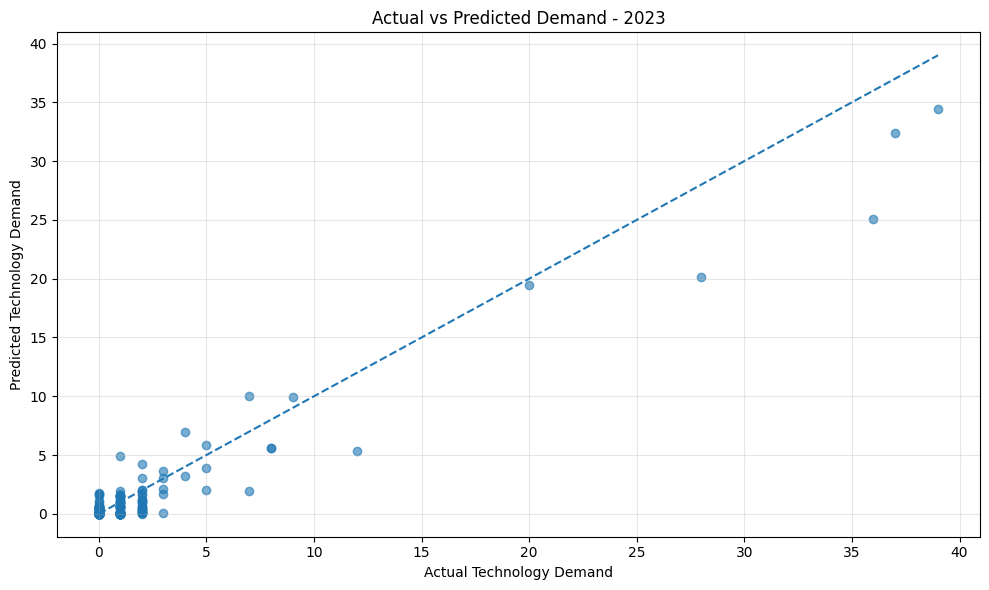

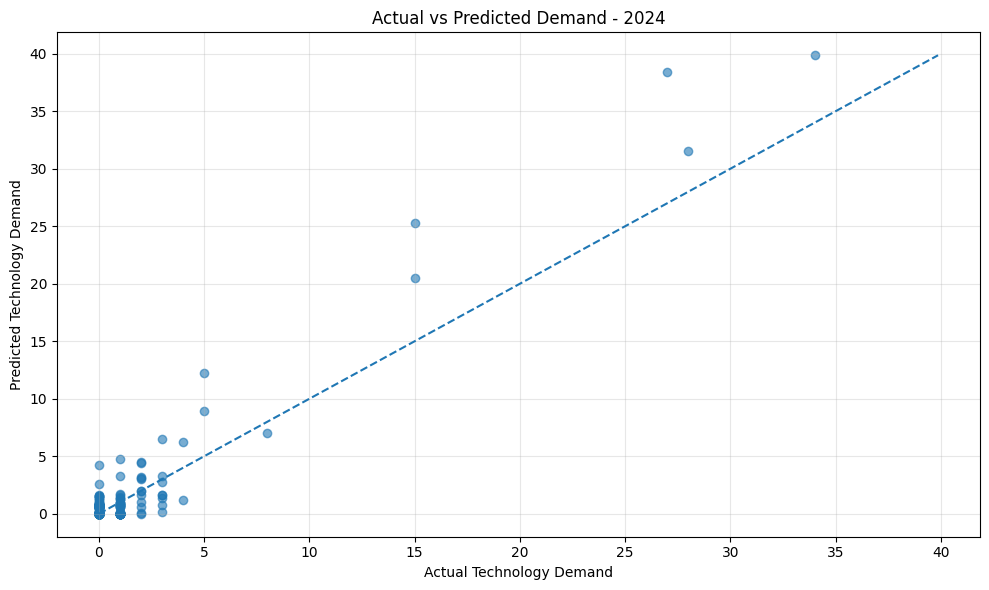

In [55]:
import matplotlib.pyplot as plt

for year in [2023, 2024]:

    actual = backtest_predictions[year]["actual"]
    predicted = backtest_predictions[year]["predicted"]

    plt.figure(figsize=(10, 6))

    plt.scatter(actual, predicted, alpha=0.6)

    min_val = min(actual.min(), predicted.min())
    max_val = max(actual.max(), predicted.max())

    plt.plot(
        [min_val, max_val],
        [min_val, max_val],
        linestyle="--"
    )

    plt.xlabel("Actual Technology Demand")
    plt.ylabel("Predicted Technology Demand")
    plt.title(f"Actual vs Predicted Demand - {year}")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

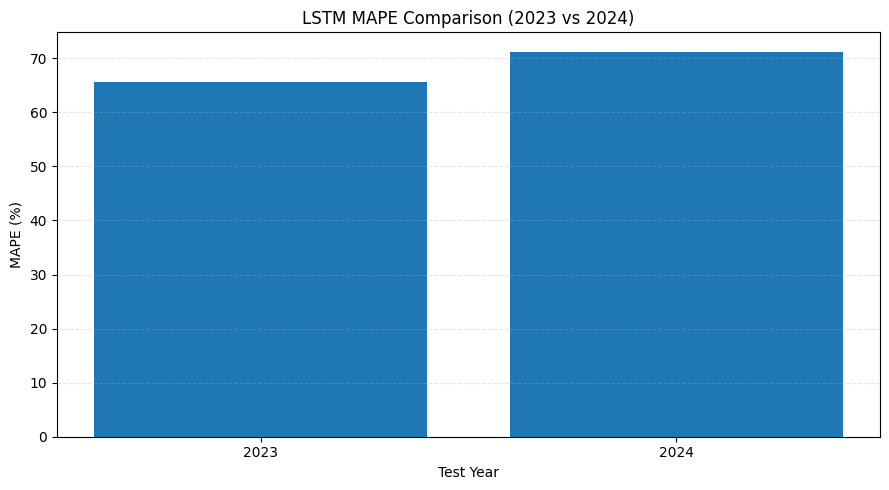

In [56]:
plt.figure(figsize=(9, 5))

plt.bar(
    backtesting_results["Test Year"].astype(str),
    backtesting_results["MAPE (%)"]
)

plt.title("LSTM MAPE Comparison (2023 vs 2024)")
plt.xlabel("Test Year")
plt.ylabel("MAPE (%)")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


In [57]:
final_evaluation = backtesting_results.copy()

final_evaluation["MAPE-based Score (%)"] = (
    100 - final_evaluation["MAPE (%)"]
)

display(final_evaluation.round(4))

,Test Year,MAE,MSE,RMSE,MAPE (%),R2 Score,MAPE-based Score (%)
0,2023,0.6908,1.9601,1.4000,65.5782,0.9158,34.4218
1,2024,0.7482,2.3856,1.5445,71.2302,0.8203,28.7698


In [58]:
for year in [2023, 2024]:

    actual = backtest_predictions[year]["actual"]
    predicted = backtest_predictions[year]["predicted"]

    error_df = pd.DataFrame({
        "Technology Domain": technology_matrix.columns,
        "Actual Demand": actual,
        "Predicted Demand": predicted
    })

    error_df["Absolute Error"] = np.abs(
        error_df["Actual Demand"] - error_df["Predicted Demand"]
    )

    print(f"\nTOP 10 PREDICTION ERRORS - {year}")

    display(
        error_df.sort_values(
            "Absolute Error",
            ascending=False
        ).head(10).round(4)
    )


TOP 10 PREDICTION ERRORS - 2023


,Technology Domain,Actual Demand,Predicted Demand,Absolute Error
54,Data Analytics,36.0,25.058500,10.9415
34,Cloud,28.0,20.161699,7.8383
109,FinTech,12.0,5.316200,6.6838
4,API,7.0,1.954900,5.0451
209,Software Development,37.0,32.408298,4.5917
3,AI/ML,39.0,34.426601,4.5734
61,Data Science,1.0,4.945900,3.9459
67,DevOps,7.0,10.020900,3.0209
164,Mobile Development,5.0,1.998200,3.0018
23,Backend/Frontend,3.0,0.029900,2.9701



TOP 10 PREDICTION ERRORS - 2024


,Technology Domain,Actual Demand,Predicted Demand,Absolute Error
209,Software Development,27.0,38.413300,11.4133
34,Cloud,15.0,25.270201,10.2702
109,FinTech,5.0,12.248500,7.2485
3,AI/ML,34.0,39.860100,5.8601
49,Cybersecurity,15.0,20.532499,5.5325
164,Mobile Development,0.0,4.211800,4.2118
16,Automation,5.0,8.954700,3.9547
4,API,1.0,4.774000,3.7740
65,Database,3.0,6.514600,3.5146
54,Data Analytics,28.0,31.496700,3.4967


In [59]:
# Historical backtesting error summary

historical_error = backtesting_results[
    ["Test Year", "MAE", "RMSE", "MAPE (%)", "R2 Score"]
].copy()

display(historical_error.round(4))

# Average historical errors
average_mae = historical_error["MAE"].mean()
average_rmse = historical_error["RMSE"].mean()
average_mape = historical_error["MAPE (%)"].mean()

print("Average Historical MAE:", round(average_mae, 4))
print("Average Historical RMSE:", round(average_rmse, 4))
print("Average Historical MAPE:", round(average_mape, 2), "%")

,Test Year,MAE,RMSE,MAPE (%),R2 Score
0,2023,0.6908,1.4000,65.5782,0.9158
1,2024,0.7482,1.5445,71.2302,0.8203


Average Historical MAE: 0.7195
Average Historical RMSE: 1.4723
Average Historical MAPE: 68.4 %


In [60]:
# Create a separate copy
future_reliability = prediction_df.copy()

# Calculate error range for each technology
future_reliability_lower = (
    prediction_df - average_mae
).clip(lower=0)

future_reliability_upper = (
    prediction_df + average_mae
)

# Display estimated range
print("AVERAGE HISTORICAL MAE:", round(average_mae, 4))

print("\n2025-2029 ESTIMATED PREDICTION RANGE")

display(future_reliability_lower.round(2))

print("\nUPPER ESTIMATED RANGE")

display(future_reliability_upper.round(2))

AVERAGE HISTORICAL MAE: 0.7195

2025-2029 ESTIMATED PREDICTION RANGE


Technology,/ It Consulting,4G/5G,5G,AI/ML,API,Adtech,Aerospace Technology,Agricultural Machinery / Automotive Manufacturing,Ai / Data,Ai / Data Science,...,Travel Technology,Traveltech / B2B Travel Technology,Tyre Manufacturing,UI/UX,Upi,Upi Technology,Vehicle Electronics,Vlsi Design,Web Development,Wordpress
Year,,,,,,,,,,,,,,,,,,,,,
2025,0.0,0.0,0.0,33.279999,0.28,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.28,0.0
2026,0.0,0.0,0.0,34.790001,0.71,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.53,0.0
2027,0.0,0.0,0.0,33.820000,0.78,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.68,0.0
2028,0.0,0.0,0.0,33.540001,0.61,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.60,0.0
2029,0.0,0.0,0.0,33.709999,0.51,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.60,0.0



UPPER ESTIMATED RANGE


Technology,/ It Consulting,4G/5G,5G,AI/ML,API,Adtech,Aerospace Technology,Agricultural Machinery / Automotive Manufacturing,Ai / Data,Ai / Data Science,...,Travel Technology,Traveltech / B2B Travel Technology,Tyre Manufacturing,UI/UX,Upi,Upi Technology,Vehicle Electronics,Vlsi Design,Web Development,Wordpress
Year,,,,,,,,,,,,,,,,,,,,,
2025,0.72,0.72,0.92,34.720001,1.72,0.77,0.72,1.37,0.76,0.78,...,0.81,0.72,1.36,0.86,0.72,1.05,1.44,0.72,2.72,1.10
2026,0.72,0.76,1.02,36.230000,2.15,0.87,0.84,1.13,1.00,0.81,...,0.72,0.79,1.04,0.93,0.77,1.06,1.16,0.72,2.97,0.72
2027,0.72,0.72,0.91,35.259998,2.22,0.79,0.85,1.05,0.94,0.76,...,0.72,0.74,0.96,0.96,0.83,0.94,1.10,0.72,3.12,0.82
2028,0.72,0.72,0.85,34.980000,2.05,0.76,0.80,1.03,0.86,0.74,...,0.72,0.73,0.96,0.90,0.80,0.90,1.10,0.72,3.04,0.91
2029,0.72,0.72,0.85,35.150002,1.95,0.77,0.78,1.02,0.86,0.75,...,0.72,0.74,0.97,0.85,0.76,0.88,1.06,0.72,3.04,0.86


In [61]:
model.save("lstm_model.keras")

In [62]:
from google.colab import files

files.download("lstm_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>